# L3 — PCA and k-Means Clustering (Ames Housing)

**What are we doing?** The Ames dataset describes about 2,900 houses with more than 200 columns (once categories are encoded). We want to answer two questions:

1. **PCA:** Can we describe the houses with far fewer columns without losing much information?
2. **k-means:** Can we automatically sort the houses into groups of similar houses, without telling the computer anything about prices?

Both methods are **unsupervised**: they never see the target `SalePrice`. We only look at the price at the end to check whether the groups make sense.

**Contents**
1. Data cleaning, encoding, and min-max scaling
2. PCA: how many components do we need?
3. k-means: choosing the number of clusters (elbow and silhouette)
4. Does the scaling method or a log transform change the result?
5. What do the principal components mean? (loadings)
6. What do the clusters look like?
7. Testing the model on invented houses
8. Bonus: interactive 3D plots and whether k-means is a good fit

**Quick glossary**
* **Feature** = a column of the dataset (e.g. `Gr Liv Area`).
* **Principal component (PC)** = a new "column" that PCA builds by mixing the old columns. PC1 captures the most variation in the data, PC2 the next most, and so on.
* **Explained variance** = how much of the total variation in the data a component captures (in %).
* **Cluster** = a group of houses that are close to each other. **Centroid** = the centre point of a cluster.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from sklearn.preprocessing import MinMaxScaler, StandardScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42
THRESHOLDS = [0.98, 0.95, 0.90, 0.80]
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

## 1. Data cleaning, encoding, and scaling

**Why do this?** PCA and k-means only work with numbers and have no way of handling missing values. They also measure *distances* between houses, so every column must be on a comparable scale.

**Cleaning (same as in the earlier labs):**

| Problem | What we do |
|---|---|
| `Order`, `PID` are just ID numbers | drop them |
| A missing value in e.g. `Alley`, `Pool QC`, `Fence`, `Garage*`, `Bsmt*` means "the house has no alley / pool / garage / ..." | fill with the category `"None"` (areas and counts get 0) |
| `Lot Frontage` is missing for 490 houses | fill with the median of the house's neighbourhood |
| `Garage Yr Blt` = 2207 (typo), or missing when there is no garage | 2207 → 2007; missing → `Year Built` |
| `Year Remod/Add` is earlier than `Year Built` | set to `Year Built` |
| `MS SubClass` is a number but really a category | treat as text |
| 3 unfinished houses (> 4000 sq ft, price < 200k) | remove. They are unusual sales and would pull the clusters away. |

We also drop columns that describe the *sale* and not the *house* (`Mo Sold`, `Yr Sold`, `Sale Type`, `Sale Condition`), so that the clusters describe houses.

**Encoding (turning text into numbers):**
* **Ordinal** columns have a natural order (`Po < Fa < TA < Gd < Ex`). We map them to 0, 1, 2, ... so the order is kept.
* **Nominal** columns have no order (`Neighborhood`, `House Style`, ...). We use **one-hot encoding**: one 0/1 column per category (e.g. `Neighborhood_OldTown` = 1 if the house is in OldTown). We do *not* use 1, 2, 3, ... for them, because k-means would think "category 3" is bigger than "category 1" and "between" 2 and 4.

**New features:** `Total SF`, `House Age`, `Total Baths` (from the feature-engineering lab).

**Scaling (min-max):** each column is squeezed into the range 0 to 1 using $x' = \frac{x - \min}{\max - \min}$. Without it, a column in square feet (values up to thousands) would completely dominate a column like `Fireplaces` (0 to 4) when distances are computed.

In [2]:
df_raw = pd.read_csv("data/AmesHousing.csv", sep="\t")

PRICE_BINS = [0, 100_000, 130_000, 180_000, 250_000, 400_000, np.inf]
CLASS_NAMES = ["<100k", "100-130k", "130-180k", "180-250k", "250-400k", ">=400k"]

NOMINAL = [
    "MS SubClass", "MS Zoning", "Street", "Alley", "Land Contour", "Lot Config",
    "Neighborhood", "Condition 1", "Condition 2", "Bldg Type", "House Style",
    "Roof Style", "Roof Matl", "Exterior 1st", "Exterior 2nd", "Mas Vnr Type",
    "Foundation", "Heating", "Central Air", "Electrical", "Garage Type", "Misc Feature",
]
QUAL = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
FIN = {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6}
ORDINAL_MAPS = {
    **{c: QUAL for c in ["Exter Qual", "Exter Cond", "Bsmt Qual", "Bsmt Cond", "Heating QC",
                         "Kitchen Qual", "Fireplace Qu", "Garage Qual", "Garage Cond", "Pool QC"]},
    "Bsmt Exposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFin Type 1": FIN, "BsmtFin Type 2": FIN,
    "Garage Finish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Functional": {"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7},
    "Paved Drive": {"N": 0, "P": 1, "Y": 2},
    "Lot Shape": {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "Land Slope": {"Sev": 0, "Mod": 1, "Gtl": 2},
    "Utilities": {"ELO": 0, "NoSeWa": 1, "NoSewr": 2, "AllPub": 3},
    "Fence": {"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
}
NONE_CAT = ["Alley", "Mas Vnr Type", "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1",
            "BsmtFin Type 2", "Fireplace Qu", "Garage Type", "Garage Finish", "Garage Qual",
            "Garage Cond", "Pool QC", "Fence", "Misc Feature"]
ZERO_NUM = ["Mas Vnr Area", "BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF",
            "Bsmt Full Bath", "Bsmt Half Bath", "Garage Cars", "Garage Area"]
DROP = ["Order", "PID", "SalePrice", "Mo Sold", "Yr Sold", "Sale Type", "Sale Condition"]
REF_YEAR = 2010  # last sale year in the data, used for House Age (so new houses get the same reference)

# Fill values learned once on the training data and reused for new houses.
FRONTAGE_BY_NBHD = df_raw.groupby("Neighborhood")["Lot Frontage"].median()
FRONTAGE_GLOBAL = df_raw["Lot Frontage"].median()
ELECTRICAL_MODE = df_raw["Electrical"].mode()[0]


def clean(df):
    df = df.drop(columns=DROP, errors="ignore").copy()
    df[NONE_CAT] = df[NONE_CAT].fillna("None")
    df[ZERO_NUM] = df[ZERO_NUM].fillna(0)
    df["Electrical"] = df["Electrical"].fillna(ELECTRICAL_MODE)
    df["Lot Frontage"] = (df["Lot Frontage"]
                          .fillna(df["Neighborhood"].map(FRONTAGE_BY_NBHD))
                          .fillna(FRONTAGE_GLOBAL))
    df.loc[df["Garage Yr Blt"] > 2010, "Garage Yr Blt"] = 2007
    df["Garage Yr Blt"] = df["Garage Yr Blt"].fillna(df["Year Built"])
    df["Year Remod/Add"] = df[["Year Remod/Add", "Year Built"]].max(axis=1)
    df["MS SubClass"] = df["MS SubClass"].astype(str)
    for col, mapping in ORDINAL_MAPS.items():
        df[col] = df[col].map(mapping).astype(float)
    df["Total SF"] = df["Gr Liv Area"] + df["Total Bsmt SF"]
    df["House Age"] = REF_YEAR - df["Year Built"]
    df["Total Baths"] = (df["Full Bath"] + 0.5 * df["Half Bath"]
                         + df["Bsmt Full Bath"] + 0.5 * df["Bsmt Half Bath"])
    return df


def encode(df_clean, columns=None):
    # One-hot encode nominal columns; `columns` aligns new data to the training columns.
    X = pd.get_dummies(df_clean, columns=NOMINAL, dtype=float)
    if columns is not None:
        X = X.reindex(columns=columns, fill_value=0.0)
    return X


outlier = (df_raw["Gr Liv Area"] > 4000) & (df_raw["SalePrice"] < 200_000)
df = df_raw.loc[~outlier].reset_index(drop=True)
price = df["SalePrice"].to_numpy()
price_class = pd.cut(price, PRICE_BINS, right=False, labels=False).astype(int)

houses = clean(df)               # cleaned, ordinal-encoded, readable (used for interpretation)
X = encode(houses)               # model matrix
FEATURES = X.columns
print(f"removed outliers: {outlier.sum()} | houses: {len(X)} | features after encoding: {X.shape[1]}")
print("missing values left:", int(X.isna().sum().sum()))

removed outliers: 3 | houses: 2927 | features after encoding: 233
missing values left: 0


In [3]:
scaler = MinMaxScaler()
X_mm = scaler.fit_transform(X)
print("min-max scaled matrix:", X_mm.shape, "| range:", X_mm.min(), "-", X_mm.max())

min-max scaled matrix: (2927, 233) | range: 0.0 - 1.0


## 2. PCA: how much variance does each component explain?

**Idea in one sentence:** many of our columns carry overlapping information (e.g. big houses also have big garages). PCA finds new directions ("principal components") that capture as much of the variation as possible, ordered from most to least important. We can then keep only the first few components.

`PCA(n_components=0.98)` means "keep as many components as needed to explain 98 % of the total variance". `explained_variance_ratio_` tells us how much each single component explains.

In [4]:
pca98 = PCA(n_components=0.98, svd_solver="full", random_state=SEED).fit(X_mm)
evr = pca98.explained_variance_ratio_
cum = np.cumsum(evr)

pca_full = PCA(svd_solver="full").fit(X_mm)
cum_full = np.cumsum(pca_full.explained_variance_ratio_)
N_PC = {t: int(np.searchsorted(cum_full, t) + 1) for t in THRESHOLDS}

print(f"original features: {X.shape[1]}  ->  components for 98 %: {pca98.n_components_}")
for t in THRESHOLDS:
    print(f"  {int(t*100)} % of the variance needs {N_PC[t]:3d} principal components "
          f"({N_PC[t] / X.shape[1]:.0%} of the features)")

evr_table = pd.DataFrame({"PC": [f"PC{i+1}" for i in range(len(evr))],
                          "explained variance %": 100 * evr, "cumulative %": 100 * cum})
display(evr_table.head(20).round(2).set_index("PC").T)
print("... (all", len(evr), "components in evr_table)")

original features: 233  ->  components for 98 %: 114
  98 % of the variance needs 114 principal components (49% of the features)
  95 % of the variance needs  82 principal components (35% of the features)
  90 % of the variance needs  59 principal components (25% of the features)
  80 % of the variance needs  35 principal components (15% of the features)


PC,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20
explained variance %,14.17,9.12,5.49,4.34,3.74,3.12,2.98,2.87,2.57,2.39,2.22,2.16,1.93,1.72,1.59,1.49,1.44,1.38,1.26,1.21
cumulative %,14.17,23.29,28.77,33.12,36.86,39.98,42.96,45.83,48.39,50.78,53.01,55.16,57.09,58.81,60.40,61.89,63.34,64.72,65.98,67.19


... (all 114 components in evr_table)


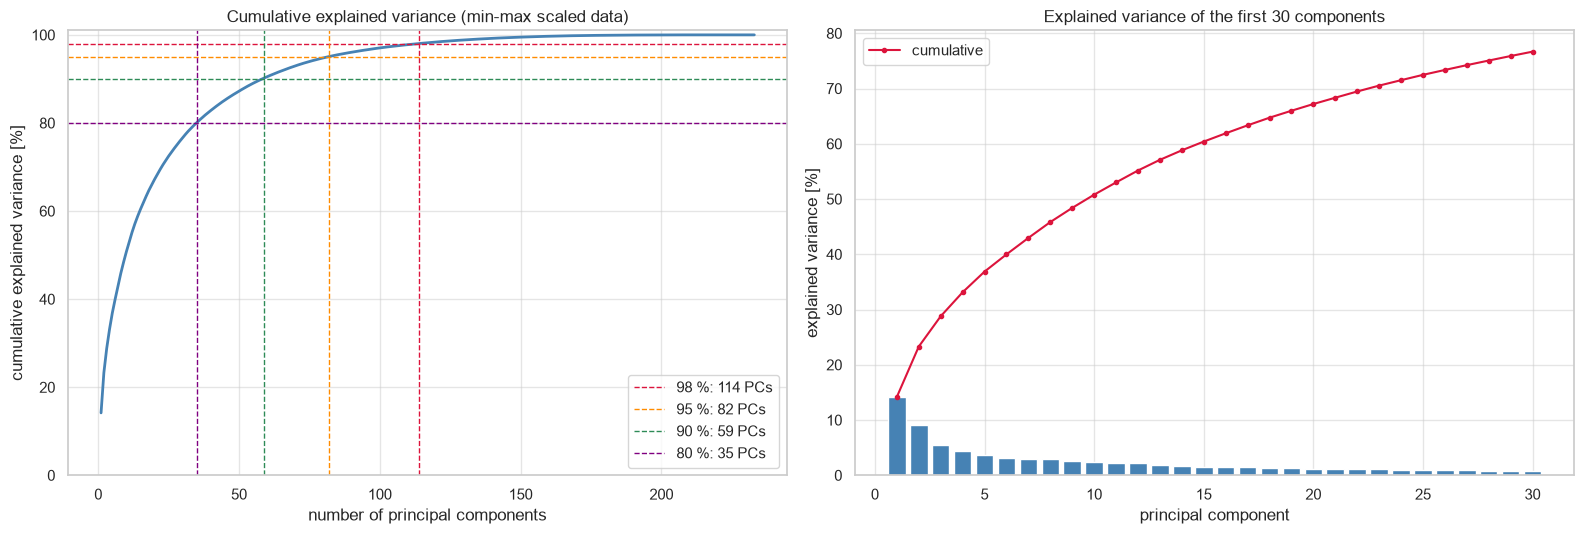

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
n_show = len(cum_full)
axes[0].plot(np.arange(1, n_show + 1), 100 * cum_full, lw=2, color="steelblue")
colors = dict(zip(THRESHOLDS, ["crimson", "darkorange", "seagreen", "purple"]))
for t in THRESHOLDS:
    axes[0].axhline(100 * t, ls="--", lw=1, color=colors[t])
    axes[0].axvline(N_PC[t], ls="--", lw=1, color=colors[t], label=f"{int(t*100)} %: {N_PC[t]} PCs")
axes[0].set(xlabel="number of principal components", ylabel="cumulative explained variance [%]",
            title="Cumulative explained variance (min-max scaled data)", ylim=(0, 101))
axes[0].legend(loc="lower right")

k = 30
axes[1].bar(np.arange(1, k + 1), 100 * pca_full.explained_variance_ratio_[:k], color="steelblue")
axes[1].plot(np.arange(1, k + 1), 100 * cum_full[:k], "o-", color="crimson", ms=3, label="cumulative")
axes[1].set(xlabel="principal component", ylabel="explained variance [%]",
            title=f"Explained variance of the first {k} components")
axes[1].legend()
plt.tight_layout(); plt.show()

### Interpretation

**Short answer:** we need **114 of the 233 columns' worth of components** to keep 98 % of the information, and only **35** to keep 80 %.

| Variance to keep | Components needed | Share of the 233 features |
|---|---|---|
| 98 % | **114** | 49 % |
| 95 % | **82** | 35 % |
| 90 % | **59** | 25 % |
| 80 % | **35** | 15 % |

* **Each component explains little.** PC1 explains only 14.2 %, PC2 9.1 %, PC3 5.5 %. After PC10 each one adds less than 2.5 %. The first 20 together reach only 67 %.
* **The curve flattens.** The first ~30 components add variance quickly, then every extra component gives very little. The last 2 % of variance alone costs about 32 extra components (82 → 114 for the step from 95 % to 98 %).
* **Why is the variance so spread out?** Of our 233 columns, 177 are 0/1 dummy columns (one per category). Dummies are mostly independent of each other (knowing the foundation type tells you little about the roof material), so PCA cannot combine them into a few strong directions. In total, the dummies hold **83 %** of the variance. Numeric columns like `Lot Area` have tiny variance after min-max scaling (≈ 0.001), because a few huge values stretch the range and squeeze everyone else close to 0.
* **Takeaway:** PCA works here, but it only halves the number of dimensions, not reduces them to 2–3 as it often does on purely numeric data.


## 3. k-means on the four reduced datasets

**How k-means works:** (1) pick *k* random centre points, (2) assign each house to its nearest centre, (3) move each centre to the average of its houses, (4) repeat 2–3 until nothing changes. We must choose *k* ourselves, so we need a method to pick a good value.

We run k-means on the data reduced to 98 %, 95 %, 90 % and 80 % of the variance.

**Elbow method.** *Inertia* = the sum of squared distances from every house to its cluster centre. It always goes down when *k* grows (more clusters = houses are closer to their centre). The best *k* is where the curve bends like an elbow: after that, adding clusters hardly helps. We detect the bend automatically as the point farthest from the straight line between the first and last point, and we also check by eye.

**Silhouette score.** For each house we compare *a* (average distance to its own cluster) and *b* (average distance to the nearest other cluster): $s = \frac{b-a}{\max(a,b)}$.
* close to **1** → the house clearly belongs to its cluster
* close to **0** → the house sits on the border between two clusters
* **negative** → the house is probably in the wrong cluster

In [6]:
K_RANGE = range(1, 13)

def elbow_k(inertias, ks):
    # Point of the curve farthest from the chord between its first and last point (kneedle idea).
    x = np.asarray(list(ks), float); y = np.asarray(inertias, float)
    xn = (x - x[0]) / (x[-1] - x[0]); yn = (y - y.min()) / (y.max() - y.min())
    dist = np.abs(yn - (1 - xn))  # chord from (0,1) to (1,0)
    return int(x[np.argmax(dist)])

def scan_k(Z, ks=K_RANGE):
    inertia, sil = [], {}
    for k in ks:
        km = KMeans(k, n_init=10, random_state=SEED).fit(Z)
        inertia.append(km.inertia_)
        if k > 1:
            sil[k] = silhouette_score(Z, km.labels_)
    return inertia, sil

Z = {t: PCA(n_components=N_PC[t], svd_solver="full", random_state=SEED).fit_transform(X_mm) for t in THRESHOLDS}
scan = {t: scan_k(Z[t]) for t in THRESHOLDS}

rows = []
for t in THRESHOLDS:
    inertia, sil = scan[t]
    rows.append({"variance": f"{int(t*100)} %", "PCs": N_PC[t], "elbow k": elbow_k(inertia, K_RANGE),
                 "best silhouette k": max(sil, key=sil.get), **{f"sil k={k}": sil[k] for k in range(2, 9)}})
scan_df = pd.DataFrame(rows).set_index("variance")
display(scan_df.round(3))

,PCs,elbow k,best silhouette k,sil k=2,sil k=3,sil k=4,sil k=5,sil k=6,sil k=7,sil k=8
variance,,,,,,,,,,
98 %,114,4,3,0.110,0.111,0.096,0.100,0.104,0.099,0.094
95 %,82,4,3,0.114,0.115,0.100,0.111,0.103,0.101,0.106
90 %,59,4,3,0.121,0.122,0.108,0.113,0.110,0.112,0.113
80 %,35,4,7,0.137,0.137,0.129,0.133,0.125,0.141,0.136


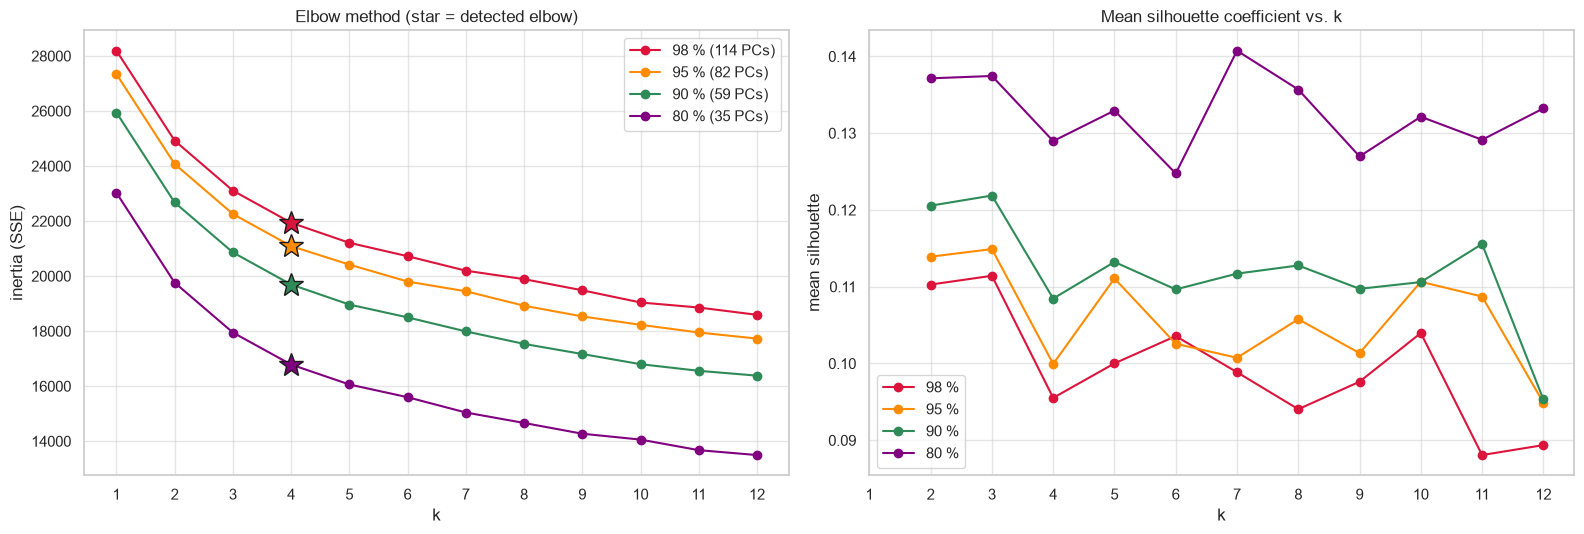

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for t in THRESHOLDS:
    inertia, sil = scan[t]
    axes[0].plot(list(K_RANGE), inertia, "o-", color=colors[t], label=f"{int(t*100)} % ({N_PC[t]} PCs)")
    axes[1].plot(list(sil), list(sil.values()), "o-", color=colors[t], label=f"{int(t*100)} %")
    ke = scan_df.loc[f"{int(t*100)} %", "elbow k"]
    axes[0].plot(ke, inertia[ke - 1], "*", ms=18, color=colors[t], mec="k")
axes[0].set(xlabel="k", ylabel="inertia (SSE)", title="Elbow method (star = detected elbow)")
axes[1].set(xlabel="k", ylabel="mean silhouette", title="Mean silhouette coefficient vs. k")
for ax in axes: ax.legend(); ax.set_xticks(list(K_RANGE))
plt.tight_layout(); plt.show()

### Silhouette plots

How to read them: each coloured band is one cluster, and every thin horizontal line in it is one house, sorted by silhouette value. The width of a band's bars shows how well-fitting the houses are, and the height of the band is the cluster size. The red dashed line is the average. A *good* clustering has bands that reach beyond the red line, have similar heights, and have almost no parts on the negative side.

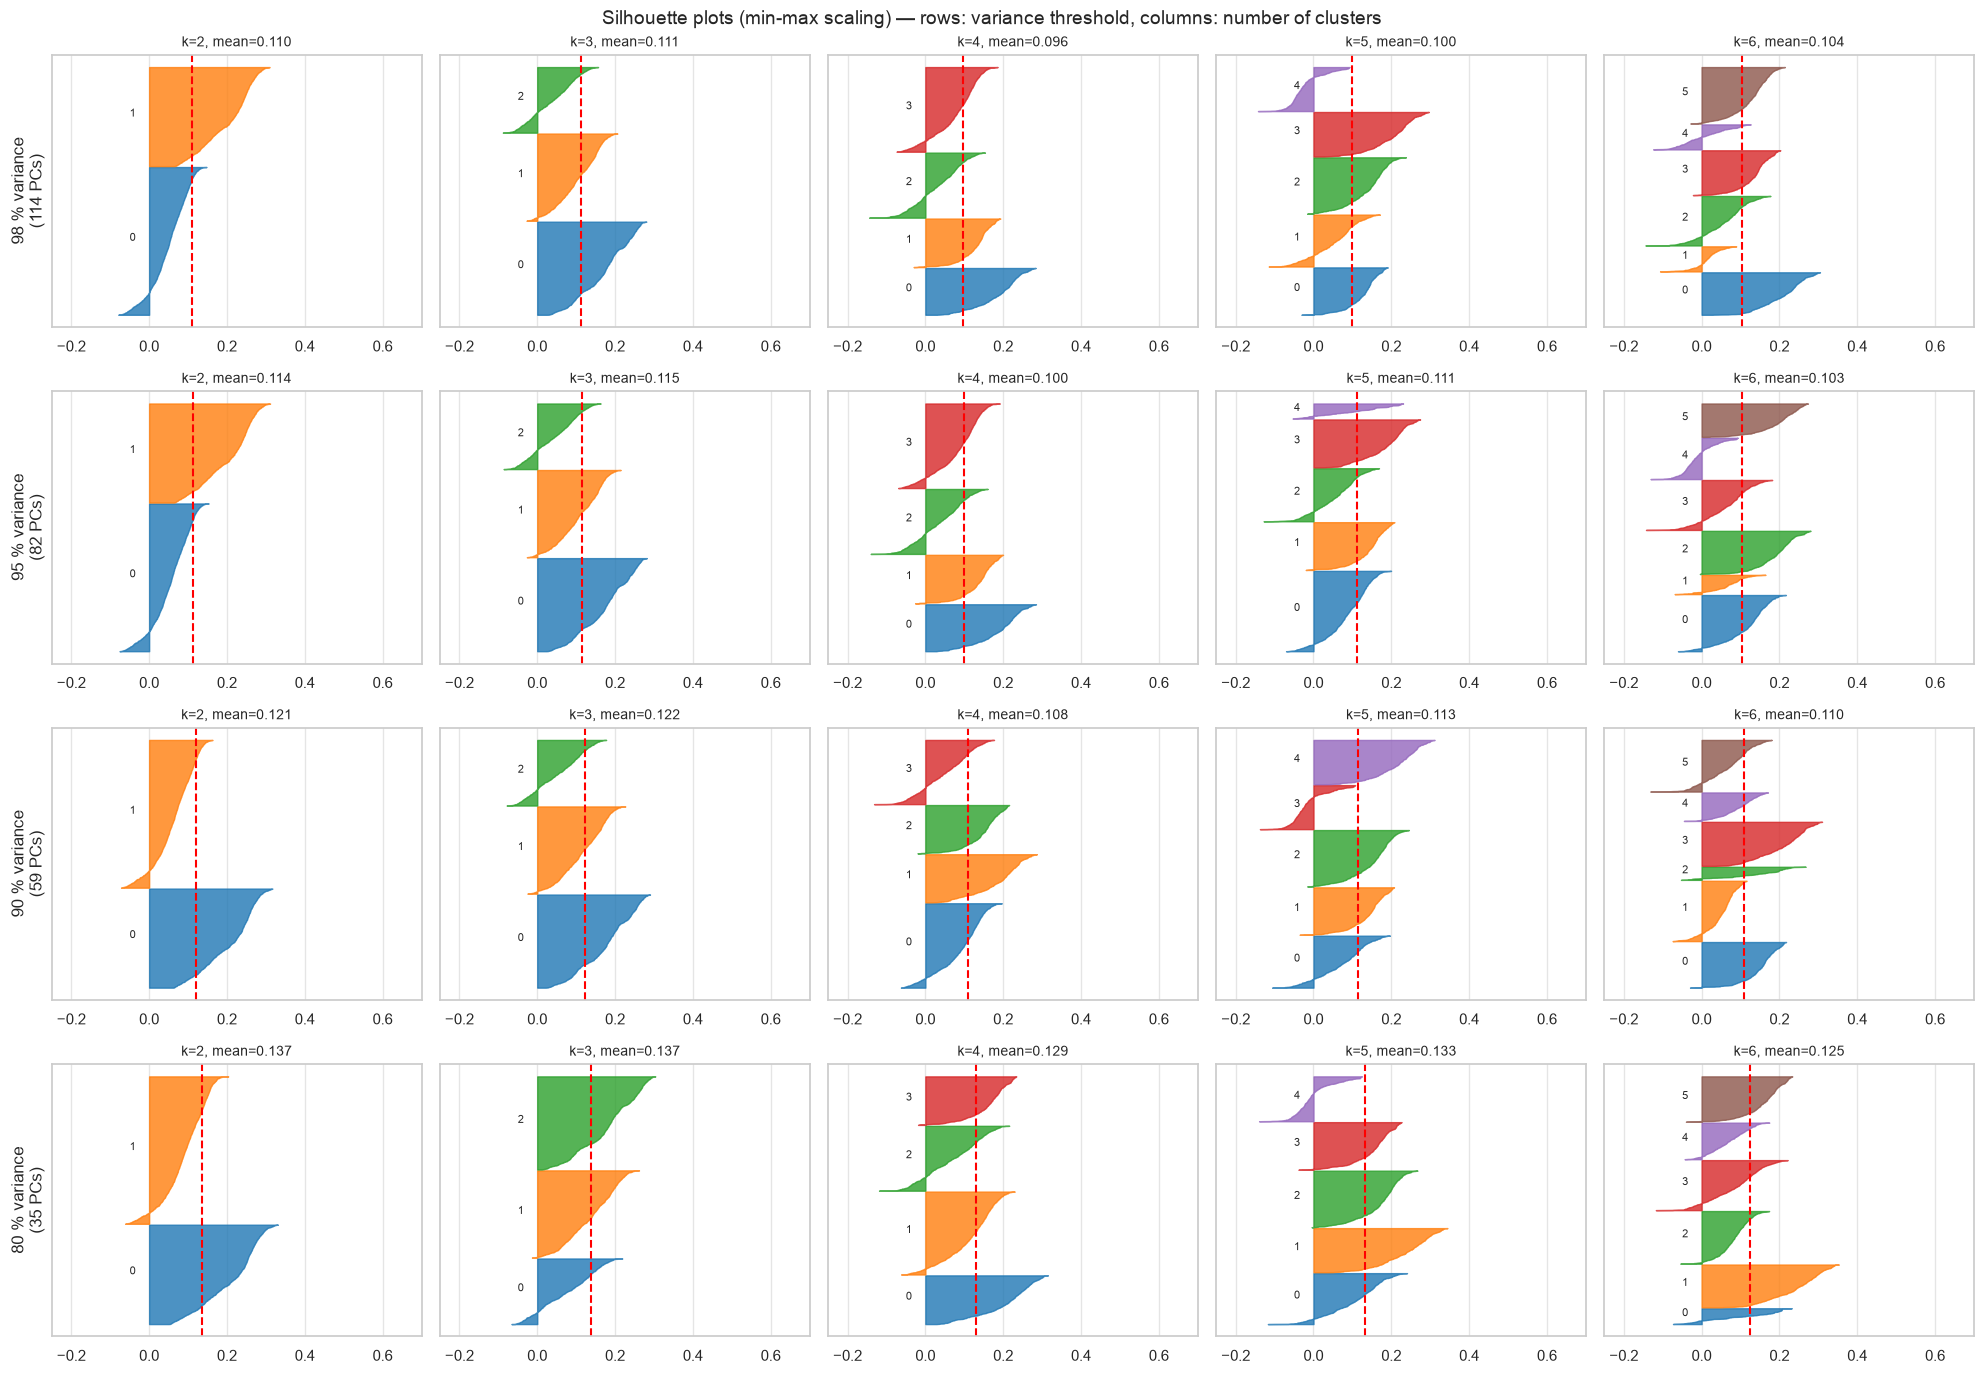

In [8]:
def silhouette_plot(ax, Zt, k):
    km = KMeans(k, n_init=10, random_state=SEED).fit(Zt)
    s = silhouette_samples(Zt, km.labels_); avg = s.mean(); y0 = 10
    for c in range(k):
        sc = np.sort(s[km.labels_ == c]); y1 = y0 + len(sc)
        ax.fill_betweenx(np.arange(y0, y1), 0, sc, color=cm.tab10(c), alpha=0.8)
        ax.text(-0.05, (y0 + y1) / 2, str(c), fontsize=8)
        y0 = y1 + 10
    ax.axvline(avg, color="red", ls="--")
    ax.set_title(f"k={k}, mean={avg:.3f}", fontsize=10); ax.set_yticks([]); ax.set_xlim(-0.25, 0.7)

SIL_KS = [2, 3, 4, 5, 6]
fig, axes = plt.subplots(len(THRESHOLDS), len(SIL_KS), figsize=(20, 14))
for i, t in enumerate(THRESHOLDS):
    for j, k in enumerate(SIL_KS):
        silhouette_plot(axes[i, j], Z[t], k)
    axes[i, 0].set_ylabel(f"{int(t*100)} % variance\n({N_PC[t]} PCs)", fontsize=12)
plt.suptitle("Silhouette plots (min-max scaling) — rows: variance threshold, columns: number of clusters", fontsize=14)
plt.tight_layout(); plt.show()

### Choice of *k*

**What the plots tell us**
* **Elbow:** for all four thresholds the automatic elbow is at **k = 4**. The curve has no sharp corner, only a gentle bend. Going from 1 to 2 to 3 clusters reduces the inertia a lot; from 4 on, every extra cluster brings only a small gain.
* **Silhouette:** all scores are low (0.09–0.14). A silhouette of 0.1 means the groups are **not clearly separated**: houses form a smooth continuum, not isolated islands. The best scores are at k = 3 for 98/95/90 % (0.111 / 0.115 / 0.122), with k = 2 almost the same. At 80 % the maximum is at k = 7, but that curve is jumpy, so we do not trust it.
* **Silhouette plots:** for k = 2 and 3 the bands are thick and almost nothing is negative. From k = 4 on, one cluster gets a clear negative tail, i.e. houses that sit between two groups.

**Our decision: k = 4**, because the task says to use the elbow method, and it costs only about 0.015 in silhouette compared to k = 3. It is also meaningful: with k = 3, all modern houses are in one cluster; with k = 4 they split into **1-story** and **2-story** houses (you can see two separate "arms" on the right of the PC1–PC2 plot in section 6).


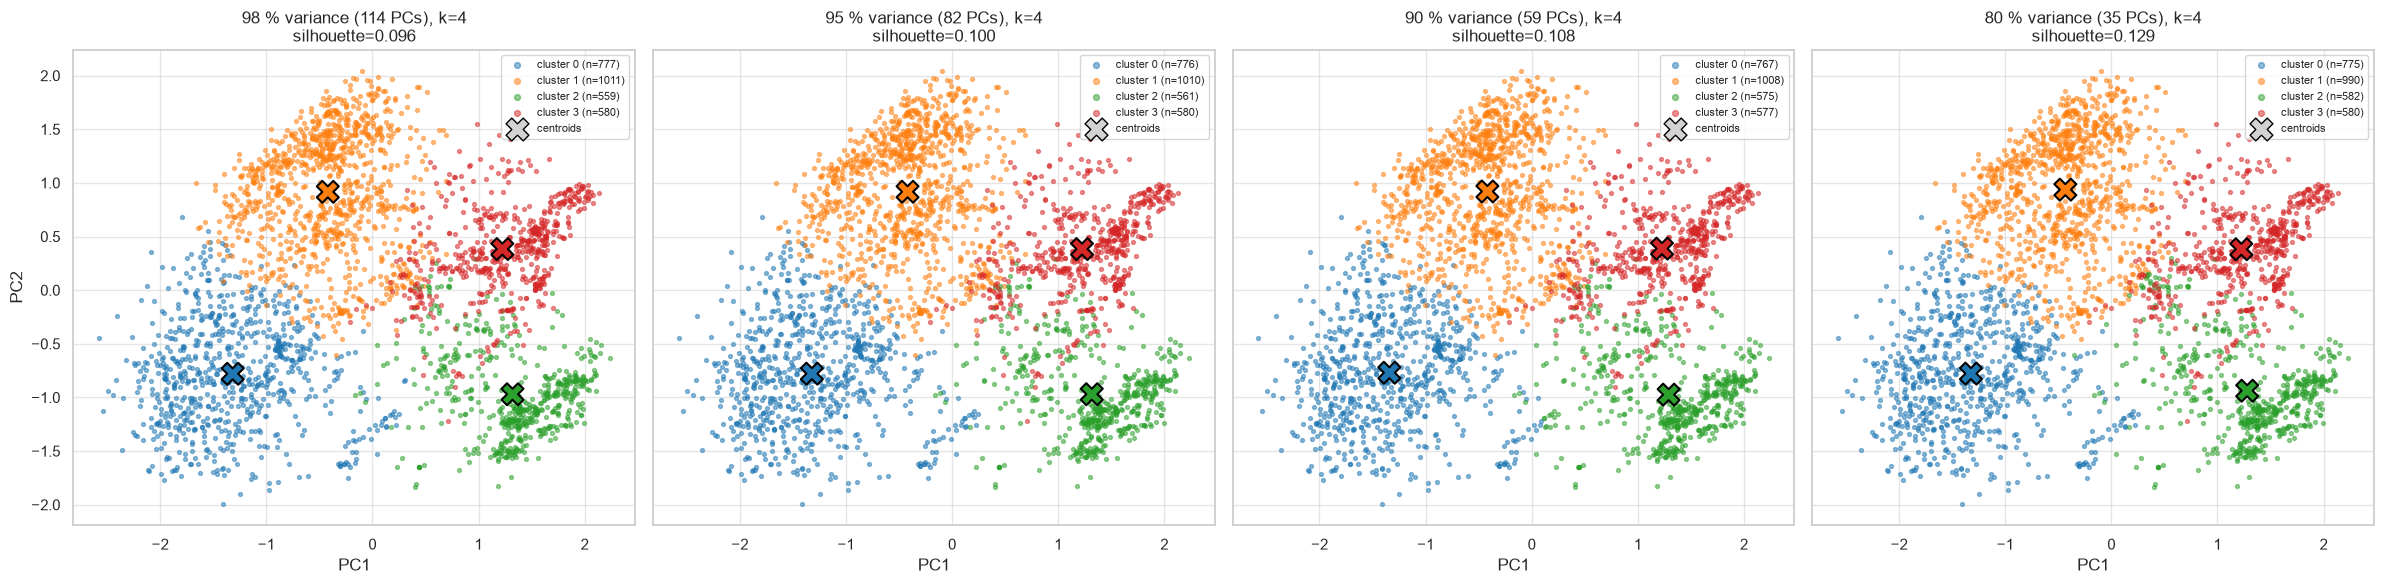

Adjusted Rand Index between the clusterings of the four thresholds (1 = identical partition):


,98 %,95 %,90 %,80 %
98 %,1.000,0.997,0.983,0.974
95 %,0.997,1.000,0.986,0.977
90 %,0.983,0.986,1.000,0.966
80 %,0.974,0.977,0.966,1.000


In [9]:
K = 4
models = {t: KMeans(K, n_init=10, random_state=SEED).fit(Z[t]) for t in THRESHOLDS}

# Relabel clusters by mean sale price (0 = cheapest) so that the colours mean the same thing in all plots.
def order_by_price(labels):
    means = pd.Series(price).groupby(labels).mean().sort_values()
    return pd.Series(labels).map({old: new for new, old in enumerate(means.index)}).to_numpy(), means.index.to_numpy()

labels, centers = {}, {}
for t in THRESHOLDS:
    labels[t], order = order_by_price(models[t].labels_)
    centers[t] = models[t].cluster_centers_[order]

fig, axes = plt.subplots(1, 4, figsize=(24, 6), sharex=True, sharey=True)
for ax, t in zip(axes, THRESHOLDS):
    for c in range(K):
        m = labels[t] == c
        ax.scatter(Z[t][m, 0], Z[t][m, 1], s=8, alpha=0.5, color=cm.tab10(c), label=f"cluster {c} (n={m.sum()})")
    ax.scatter(centers[t][:, 0], centers[t][:, 1], marker="X", s=250, c=[cm.tab10(c) for c in range(K)],
               edgecolor="black", linewidth=1.5)
    ax.scatter([], [], marker="X", s=120, c="lightgrey", edgecolor="black", label="centroids")
    ax.set(title=f"{int(t*100)} % variance ({N_PC[t]} PCs), k={K}\nsilhouette={silhouette_score(Z[t], labels[t]):.3f}",
           xlabel="PC1")
    ax.legend(fontsize=8, markerscale=1.5)
axes[0].set_ylabel("PC2")
plt.tight_layout(); plt.show()

ari = pd.DataFrame([[adjusted_rand_score(labels[a], labels[b]) for b in THRESHOLDS] for a in THRESHOLDS],
                   index=[f"{int(t*100)} %" for t in THRESHOLDS], columns=[f"{int(t*100)} %" for t in THRESHOLDS])
print("Adjusted Rand Index between the clusterings of the four thresholds (1 = identical partition):")
display(ari.round(3))

### Are there differences between the thresholds?

**Almost no difference.** The four scatter plots look nearly identical, and the *Adjusted Rand Index* (ARI, 1 = identical grouping) between any two of them is **0.97–1.00**. That means fewer than 2–3 % of the houses change cluster.

**Why?** k-means decides based on distances. The components we throw away (e.g. PC36–PC114 when keeping 80 %) have very small variance, so they barely change any distance. The cluster structure is already contained in the first few components (PC1–PC3).

What *does* change:
* The **silhouette gets higher** with fewer components (0.096 → 0.129 at k = 4). This is not because the grouping is better. With fewer dimensions there is less "noise distance", so points simply look closer to their own cluster.
* **Computing time** drops (35 columns instead of 114).

**Takeaway:** keeping 80 % of the variance is enough for clustering and loses practically nothing.


## 4. Scaling method and log transformation

Up to now we used min-max scaling. Does the result change with another scaling method, or after taking the logarithm of skewed columns? We test:

* **Min-max:** every column goes to [0, 1].
* **Standardisation (z-score):** every column gets mean 0 and standard deviation 1. A rare category (e.g. only 1 % of the houses) then gets very large values, so rare categories become very important.
* **Normalisation (L2 `Normalizer`):** scales each *house* (each row) to length 1. This is different from the other two, which work per *column*. On raw data, columns with huge numbers (`Lot Area` ≈ 10 000, years ≈ 2000) dominate. We also try the more sensible *min-max first, then L2*.

(The task says "Normalisierung" without defining it, so we show both common meanings: z-score and L2.)

**Log transformation:** some columns are *right-skewed*: most values are small, a few are huge (e.g. `Lot Area`). `log1p(x) = log(1 + x)` squeezes the huge values together. We only apply it to continuous, positive, strongly skewed columns (areas). A log makes no sense for 0/1 dummies or for ratings like 1–10.

In [10]:
cont = [c for c in houses.select_dtypes("number").columns
        if houses[c].nunique() > 20 and houses[c].min() >= 0 and c not in ("Year Built", "Year Remod/Add", "Garage Yr Blt")]
SKEWED = [c for c in cont if houses[c].skew() > 0.75]
print("log1p applied to:", SKEWED)

def log_transform(Xdf):
    Xdf = Xdf.copy(); Xdf[SKEWED] = np.log1p(Xdf[SKEWED]); return Xdf

skew_cmp = pd.DataFrame({"skew raw": houses[SKEWED].skew(), "skew log1p": np.log1p(houses[SKEWED]).skew()})
display(skew_cmp.round(2).T)

SCALERS = {
    "min-max": lambda: MinMaxScaler(),
    "standard (z-score)": lambda: StandardScaler(),
    "L2 normalizer (raw)": lambda: Normalizer(),
    "min-max + L2 normalizer": lambda: _MinMaxL2(),
}

class _MinMaxL2:
    def fit_transform(self, A):
        return Normalizer().fit_transform(MinMaxScaler().fit_transform(A))

variants, rows = {}, []
for log in (False, True):
    Xv = log_transform(X) if log else X
    for name, make in SCALERS.items():
        Xs = make().fit_transform(Xv.to_numpy(float))
        p = PCA(n_components=0.98, svd_solver="full", random_state=SEED).fit(Xs)
        Zv = p.transform(Xs)
        inertia, sil = scan_k(Zv, range(1, 11))
        ke = elbow_k(inertia, range(1, 11)); kb = max(sil, key=sil.get)
        km = KMeans(K, n_init=10, random_state=SEED).fit(Zv)
        lab, order = order_by_price(km.labels_)
        key = (name, log)
        variants[key] = dict(Z=Zv, labels=lab, centers=km.cluster_centers_[order], pca=p)
        rows.append({"scaler": name, "log1p": log, "PCs for 98 %": p.n_components_,
                     "PC1 var %": 100 * p.explained_variance_ratio_[0],
                     "elbow k": ke, "best silhouette k": kb, "best silhouette": sil[kb],
                     f"silhouette k={K}": sil[K],
                     f"ARI vs min-max (k={K})": adjusted_rand_score(labels[0.98], lab),
                     f"ARI vs price class (k={K})": adjusted_rand_score(price_class, lab)})
variant_df = pd.DataFrame(rows)
display(variant_df.round(3))

log1p applied to: ['Lot Frontage', 'Lot Area', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Misc Val']


,Lot Frontage,Lot Area,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Misc Val
skew raw,1.10,13.19,2.60,0.83,4.14,0.92,0.95,0.87,12.11,0.98,1.84,2.50,4.01,11.40,3.96,22.23
skew log1p,-1.06,-0.53,0.54,-0.62,2.45,-2.14,-0.00,0.31,8.57,-0.04,0.16,-0.05,1.97,8.84,2.95,5.24


,scaler,log1p,PCs for 98 %,PC1 var %,elbow k,best silhouette k,best silhouette,silhouette k=4,ARI vs min-max (k=4),ARI vs price class (k=4)
0,min-max,False,114,14.167,4,3,0.111,0.096,1.000,0.143
1,standard (z-score),False,166,7.806,3,2,0.068,0.020,0.723,0.182
2,L2 normalizer (raw),False,8,71.466,3,2,0.599,0.258,0.034,0.002
3,min-max + L2 normalizer,False,115,13.040,4,3,0.107,0.083,0.875,0.138
4,min-max,True,115,13.913,4,3,0.110,0.099,0.889,0.138
5,standard (z-score),True,164,7.914,4,2,0.068,0.039,0.615,0.179
6,L2 normalizer (raw),True,3,82.040,3,2,0.429,0.325,0.079,0.213
7,min-max + L2 normalizer,True,115,12.696,4,3,0.106,0.086,0.846,0.131


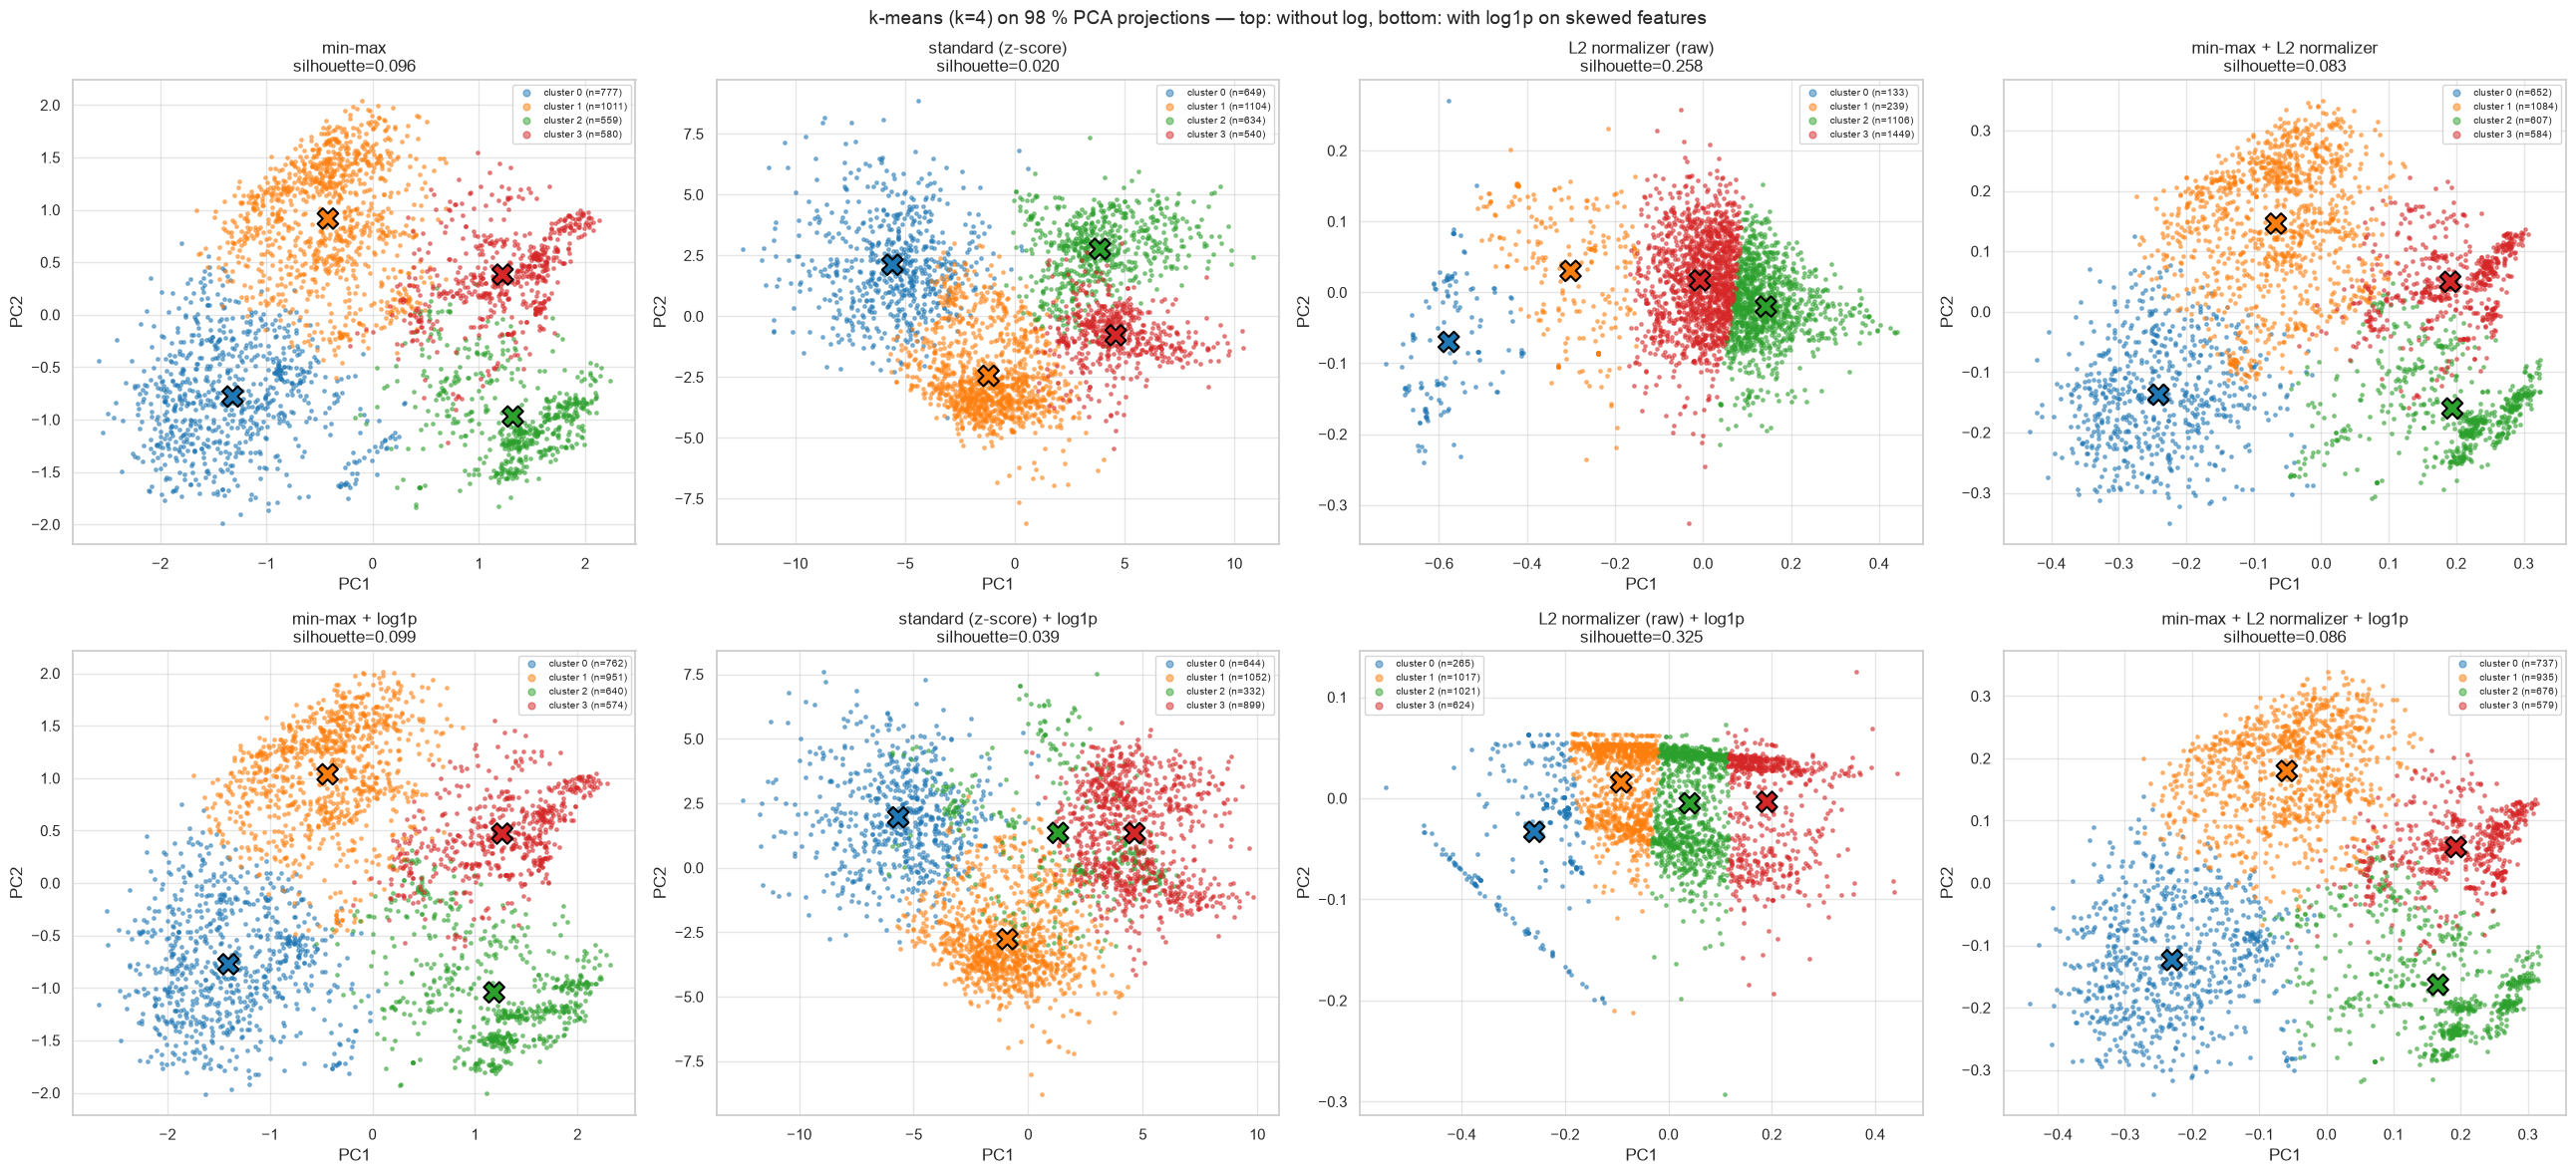

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(26, 12))
for i, log in enumerate((False, True)):
    for j, name in enumerate(SCALERS):
        v = variants[(name, log)]; ax = axes[i, j]
        for c in range(K):
            m = v["labels"] == c
            ax.scatter(v["Z"][m, 0], v["Z"][m, 1], s=6, alpha=0.5, color=cm.tab10(c), label=f"cluster {c} (n={m.sum()})")
        ax.scatter(v["centers"][:, 0], v["centers"][:, 1], marker="X", s=220, c=[cm.tab10(c) for c in range(K)],
                   edgecolor="black", linewidth=1.5)
        ax.set(title=f"{name}{' + log1p' if log else ''}\nsilhouette={silhouette_score(v['Z'], v['labels']):.3f}",
               xlabel="PC1", ylabel="PC2")
        ax.legend(fontsize=7, markerscale=2)
plt.suptitle(f"k-means (k={K}) on 98 % PCA projections — top: without log, bottom: with log1p on skewed features", fontsize=14)
plt.tight_layout(); plt.show()

In [12]:
# Which features dominate PC1 under each scaler? This explains why the clusterings differ.
top = {}
for log in (False, True):
    for name in SCALERS:
        p = variants[(name, log)]["pca"]
        load = pd.Series(np.abs(p.components_[0]), index=FEATURES).sort_values(ascending=False)
        top[f"{name}{' + log' if log else ''}"] = [f"{f} ({w:.2f})" for f, w in load.head(5).items()]
display(pd.DataFrame(top, index=[f"#{i+1}" for i in range(5)]).T)

,#1,#2,#3,#4,#5
min-max,Foundation_PConc (0.32),Exterior 1st_VinylSd (0.28),Exterior 2nd_VinylSd (0.28),Garage Type_Attchd (0.23),Garage Type_Detchd (0.22)
standard (z-score),Year Built (0.20),House Age (0.20),Garage Yr Blt (0.19),Overall Qual (0.19),Exter Qual (0.17)
L2 normalizer (raw),Lot Area (0.62),Year Remod/Add (0.36),Garage Yr Blt (0.36),Year Built (0.36),Total SF (0.35)
min-max + L2 normalizer,Foundation_PConc (0.31),Exterior 1st_VinylSd (0.27),Exterior 2nd_VinylSd (0.27),Garage Type_Detchd (0.25),Mas Vnr Type_None (0.24)
min-max + log,Foundation_PConc (0.30),Exterior 1st_VinylSd (0.26),Exterior 2nd_VinylSd (0.26),Garage Type_Attchd (0.23),Mas Vnr Type_None (0.22)
standard (z-score) + log,Year Built (0.20),House Age (0.20),Garage Yr Blt (0.19),Overall Qual (0.18),Garage Cars (0.17)
L2 normalizer (raw) + log,Total SF (0.69),Total Bsmt SF (0.39),Year Remod/Add (0.35),Garage Yr Blt (0.35),Year Built (0.34)
min-max + L2 normalizer + log,Foundation_PConc (0.29),Exterior 1st_VinylSd (0.25),Mas Vnr Type_None (0.25),Exterior 2nd_VinylSd (0.25),Garage Type_Detchd (0.24)


### Interpretation: scaling and log transformation

**Takeaway first:** *how* we scale changes the clusters much more than how many components we keep. Min-max is the most stable choice for this dataset.

**Min-max vs. z-score**
* With z-score, PCA needs **166 instead of 114** components, and PC1 explains only 7.8 % instead of 14.2 %. Reason: z-score gives *every* column the same weight, including very rare dummies. A category that appears in 0.3 % of the houses gets values around 18 standard deviations away from the mean, so each rare category creates its own direction.
* The silhouette drops to **0.02–0.07** (min-max: about 0.1), so the groups are even less clear.
* The clusters only partly agree with min-max (ARI ≈ 0.72). Interestingly, they match the **price classes** a bit better (ARI 0.18 vs. 0.14), because quality and size columns get more weight relative to the dummies.

**L2 normalisation**
* On **raw data** the biggest numbers win: `Lot Area` (≈ 10 000), years (≈ 2000), square feet. Just 8 components (3 with log) give 98 %, and PC1 alone explains 71 %. The clusters mostly encode "lot area versus year", a scale accident. The high silhouette (0.6 at k = 2) is **misleading**: it only separates a few houses with huge lots from the rest. Agreement with price classes is ≈ 0.
* **Min-max first, then L2** is reasonable. Each house is scaled to length 1, so only its *profile* matters, not its overall size. The result is very close to plain min-max (ARI 0.88).

**Log transformation**
* It really reduces skew (e.g. `Lot Area` skewness 13.2 → −0.5, `Gr Liv Area` 0.98 → −0.04). Columns that are mostly 0 (`3Ssn Porch`, `Low Qual Fin SF`, `Misc Val`) stay skewed, because a log cannot fix a big pile of zeros.
* **Min-max: almost no effect** (ARI 0.89, silhouette 0.096 → 0.099). Min-max is mainly driven by the dummies and the years, which we do not log.
* **Z-score: some effect** (silhouette 0.020 → 0.039). Extreme values (huge lots) no longer reach |z| > 10, so fewer tiny outlier clusters appear.
* **L2 on raw data: big effect.** Without `Lot Area` dominating, PC1 becomes about total size and years, and the clusters become size bands that match the price better (ARI 0.21). It is still not a good method, since only 3 components remain.

**Conclusion:** the scaler decides which columns "count" in the distance. For a dataset with many 0/1 columns plus numeric columns, min-max (with or without log) gives the most stable and easiest-to-explain clusters.


## 5. Which features make up the most important principal components?

Each principal component is a *mixture* of the original features. The **loadings** tell us how much each feature contributes to a component: `loadings = pca.components_.T * np.sqrt(pca.explained_variance_)`.

* A loading far from 0 (positive or negative) → this feature is important for that component.
* Same sign → the features go "together"; opposite sign → they go "against each other".

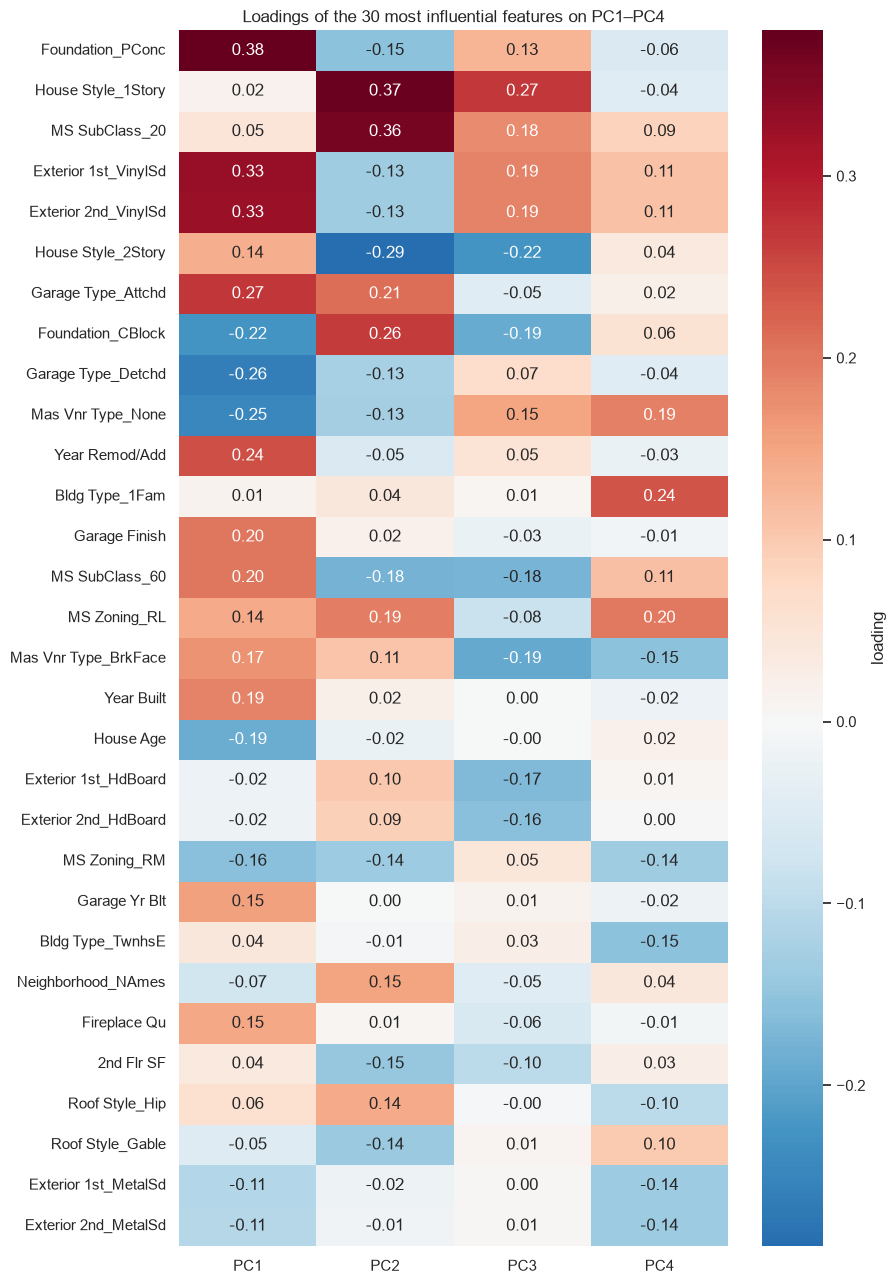

In [13]:
loadings = pd.DataFrame(pca98.components_.T * np.sqrt(pca98.explained_variance_), index=FEATURES,
                        columns=[f"PC{i+1}" for i in range(pca98.n_components_)])
N_TOP_PC = 4
top_feats = loadings.iloc[:, :N_TOP_PC].abs().max(axis=1).sort_values(ascending=False).head(30).index

plt.figure(figsize=(9, 13))
sns.heatmap(loadings.loc[top_feats].iloc[:, :N_TOP_PC], cmap="RdBu_r", center=0, annot=True, fmt=".2f", cbar_kws={"label": "loading"})
plt.title(f"Loadings of the 30 most influential features on PC1–PC{N_TOP_PC}")
plt.tight_layout(); plt.show()

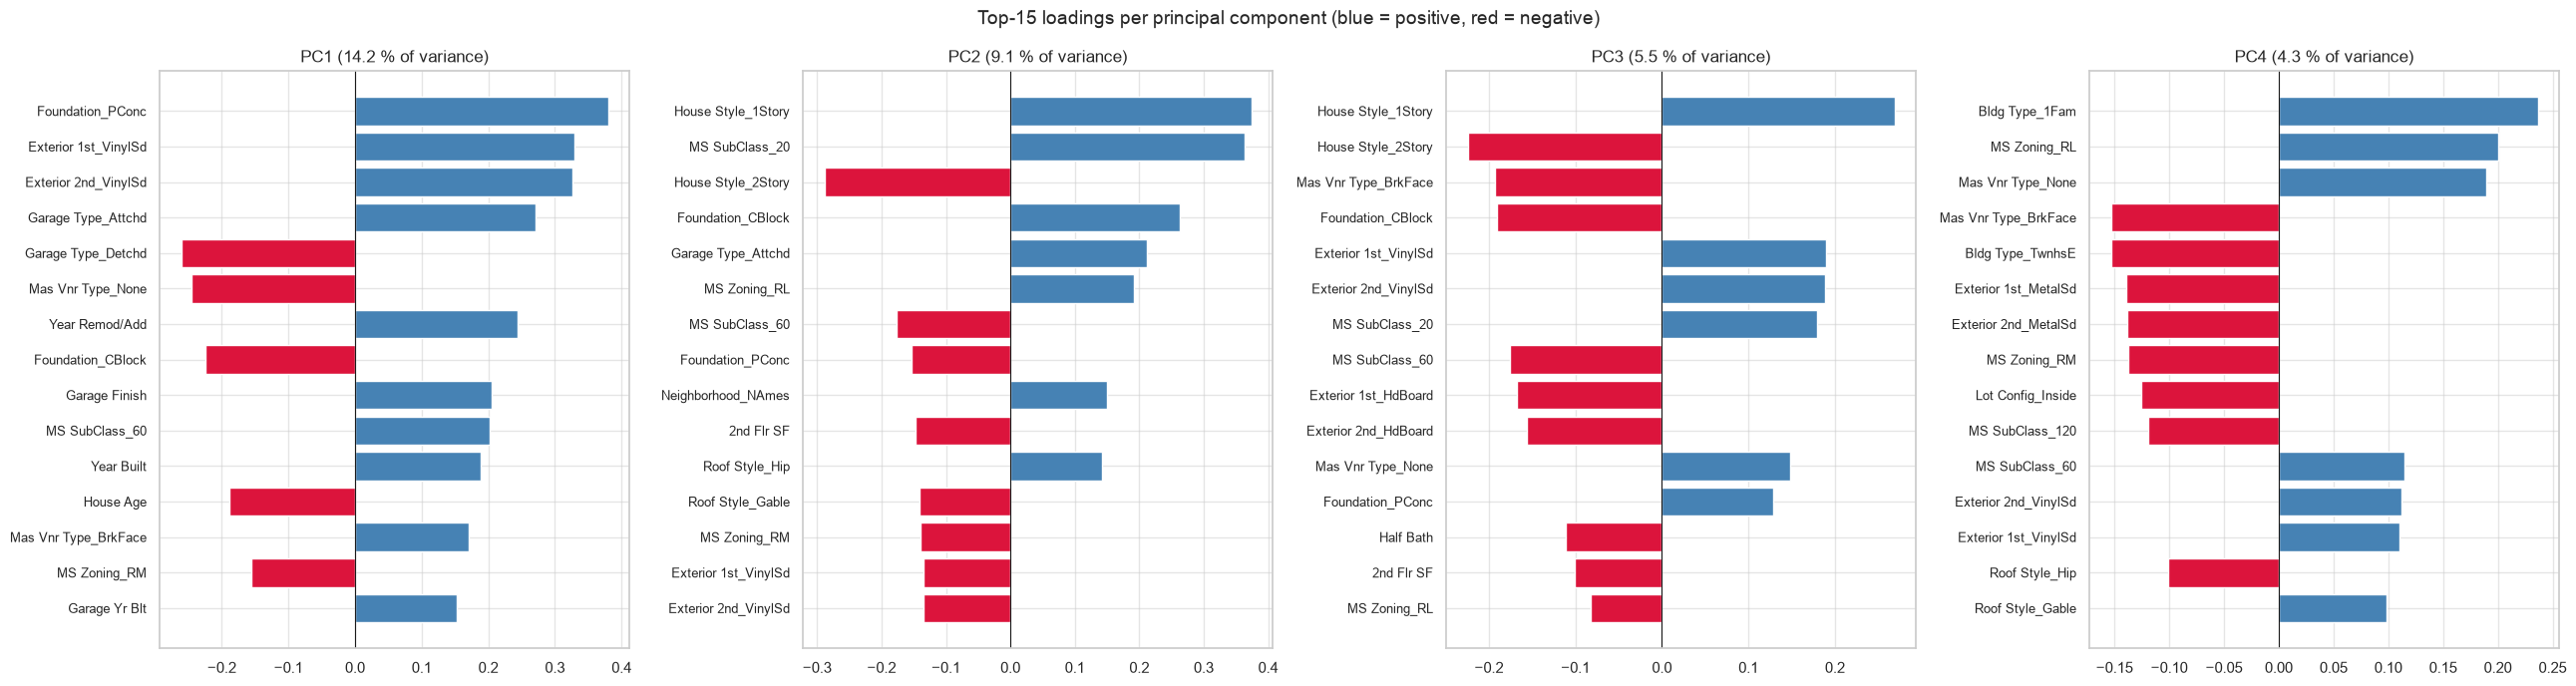

In [14]:
fig, axes = plt.subplots(1, N_TOP_PC, figsize=(26, 7))
for i, ax in enumerate(axes):
    s = loadings.iloc[:, i]; s = s.reindex(s.abs().sort_values(ascending=False).index).head(15)[::-1]
    ax.barh(s.index, s.values, color=["crimson" if v < 0 else "steelblue" for v in s.values])
    ax.set_title(f"PC{i+1} ({100 * evr[i]:.1f} % of variance)"); ax.axvline(0, color="k", lw=0.8)
    ax.tick_params(axis="y", labelsize=9)
plt.suptitle("Top-15 loadings per principal component (blue = positive, red = negative)", fontsize=14)
plt.tight_layout(); plt.show()

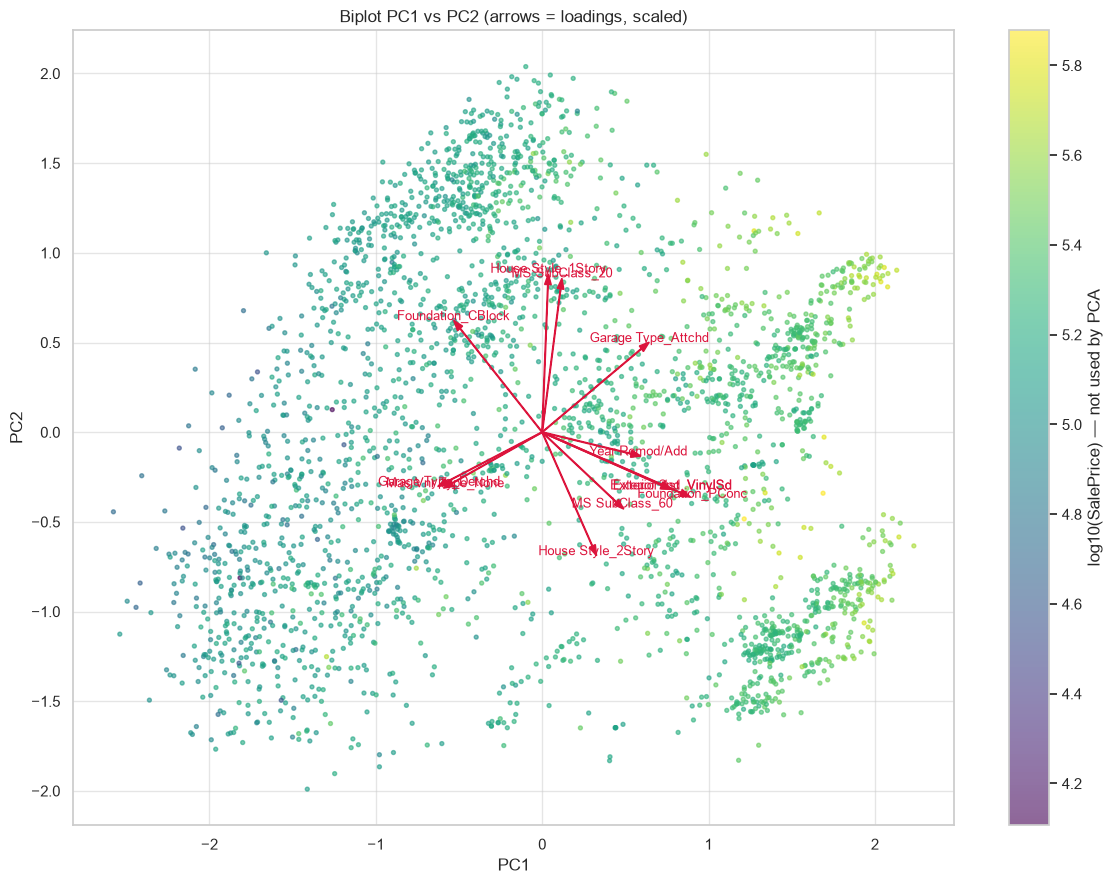

In [15]:
# Biplot: houses in PC1/PC2 with the 12 strongest feature arrows.
Z98 = Z[0.98]
arrow_feats = (loadings[["PC1", "PC2"]] ** 2).sum(axis=1).sort_values(ascending=False).head(12).index
fig, ax = plt.subplots(figsize=(12, 9))
sc = ax.scatter(Z98[:, 0], Z98[:, 1], c=np.log10(price), cmap="viridis", s=8, alpha=0.6)
plt.colorbar(sc, label="log10(SalePrice) — not used by PCA")
scale = 2.2
for f in arrow_feats:
    x, y = loadings.loc[f, ["PC1", "PC2"]] * scale
    ax.arrow(0, 0, x, y, color="crimson", width=0.004, head_width=0.04)
    ax.text(x * 1.08, y * 1.08, f, color="crimson", fontsize=9, ha="center")
ax.set(xlabel="PC1", ylabel="PC2", title="Biplot PC1 vs PC2 (arrows = loadings, scaled)")
plt.tight_layout(); plt.show()

### Interpretation of the components

* **PC1 (14.2 %) = "modern vs. old construction".** Positive: concrete foundation (`Foundation_PConc`), vinyl siding, attached garage, high `Year Built` / `Year Remod/Add`. Negative: detached garage, cinder-block foundation, `House Age`. In short: **how new the house is**. PC1 correlates **0.80** with `SalePrice`, as strongly as `Overall Qual`, even though PCA never saw the price. In the biplot, the colour (price) gets brighter from left to right.
* **PC2 (9.1 %) = "1-story vs. 2-story".** Positive: `House Style_1Story`, `MS SubClass_20`, cinder-block foundation. Negative: `2Story`, `MS SubClass_60`, `2nd Flr SF`. Correlation with price ≈ 0: this axis has **nothing to do with value**.
* **PC3 (5.5 %)** again 1-story vs. 2-story, but *within the modern houses* (vinyl siding vs. hardboard). It separates clusters 2 and 3.
* **PC4 (4.3 %) = building type:** detached single-family house vs. townhouse.

**Why do dummies dominate?** After min-max scaling, a 0/1 column can have the largest possible spread, while a numeric size column like `Gr Liv Area` is squeezed by a few very large houses. PCA looks for *variance*, so it prefers the dummies. Important for later: **the largest components describe *how a house was built*, not *how much it is worth*.**


## 6. Cluster profiles

We use the main model: **min-max scaling, 98 % variance, k = 4**. Clusters are numbered by average price (0 = cheapest) so colours mean the same thing everywhere. The tables show the average of the *original* (unscaled) features and the most common categories in each cluster.

In [16]:
cl = labels[0.98]
prof = df.assign(cluster=cl, **{"Total SF": houses["Total SF"], "House Age": houses["House Age"],
                                "Total Baths": houses["Total Baths"], "Kitchen Qual (0-5)": houses["Kitchen Qual"],
                                "Exter Qual (0-5)": houses["Exter Qual"], "Bsmt Qual (0-5)": houses["Bsmt Qual"]})
num_cols = ["SalePrice", "Overall Qual", "Overall Cond", "Gr Liv Area", "Total SF", "1st Flr SF", "2nd Flr SF",
            "Total Bsmt SF", "Year Built", "House Age", "Year Remod/Add", "Total Baths", "Bedroom AbvGr",
            "Garage Cars", "Fireplaces", "Lot Area", "Kitchen Qual (0-5)", "Exter Qual (0-5)", "Bsmt Qual (0-5)"]
summary = prof.groupby("cluster")[num_cols].mean().T
summary.loc["n houses"] = prof["cluster"].value_counts().sort_index()
summary.loc["SalePrice median"] = prof.groupby("cluster")["SalePrice"].median()
display(summary.round(1))

def top_cats(col, n=3):
    return prof.groupby("cluster")[col].agg(lambda s: ", ".join(f"{k} {v:.0%}" for k, v in s.value_counts(normalize=True).head(n).items()))
cat_cols = ["Neighborhood", "House Style", "Bldg Type", "Foundation", "MS Zoning", "Garage Type", "Central Air", "Exterior 1st"]
display(pd.DataFrame({c: top_cats(c) for c in cat_cols}).T)

cluster,0,1,2,3
SalePrice,126112.7,153703.7,241486.6,242808.3
Overall Qual,5.2,5.5,7.1,7.3
Overall Cond,5.9,5.8,5.2,5.1
Gr Liv Area,1376.9,1306.0,1975.3,1524.6
Total SF,2120.7,2354.6,2977.1,3020.8
1st Flr SF,900.7,1204.3,1047.8,1519.7
2nd Flr SF,460.0,100.7,927.3,4.9
Total Bsmt SF,744.8,1048.6,1001.8,1496.1
Year Built,1936.1,1965.7,1998.5,2002.1
House Age,73.9,44.3,11.5,7.9


cluster,0,1,2,3
Neighborhood,"OldTown 29%, BrkSide 13%, IDOTRR 12%","NAmes 38%, Sawyer 13%, NWAmes 10%","Gilbert 24%, CollgCr 17%, Somerst 11%","CollgCr 23%, NridgHt 19%, Somerst 16%"
House Style,"1.5Fin 36%, 2Story 32%, 1Story 23%","1Story 74%, SLvl 9%, 2Story 9%","2Story 95%, SLvl 4%, 1.5Fin 1%","1Story 96%, SFoyer 2%, SLvl 2%"
Bldg Type,"1Fam 75%, Twnhs 8%, 2fmCon 6%","1Fam 88%, Duplex 6%, TwnhsE 3%","1Fam 95%, Twnhs 2%, TwnhsE 2%","1Fam 71%, TwnhsE 26%, Twnhs 2%"
Foundation,"BrkTil 39%, CBlock 37%, PConc 19%","CBlock 91%, PConc 7%, Slab 2%","PConc 93%, CBlock 6%, Wood 0%","PConc 98%, CBlock 1%, Wood 0%"
MS Zoning,"RM 51%, RL 40%, FV 4%","RL 98%, RM 2%, RH 0%","RL 89%, FV 10%, RM 1%","RL 81%, FV 9%, RM 8%"
Garage Type,"Detchd 81%, Attchd 13%, BuiltIn 2%","Attchd 73%, Detchd 21%, Basment 2%","Attchd 68%, BuiltIn 28%, Detchd 4%","Attchd 96%, Detchd 3%, Basment 1%"
Central Air,"Y 77%, N 23%","Y 98%, N 2%",Y 100%,Y 100%
Exterior 1st,"Wd Sdng 31%, MetalSd 31%, VinylSd 10%","HdBoard 32%, Plywood 18%, Wd Sdng 16%","VinylSd 77%, HdBoard 11%, CemntBd 4%","VinylSd 74%, CemntBd 9%, MetalSd 8%"


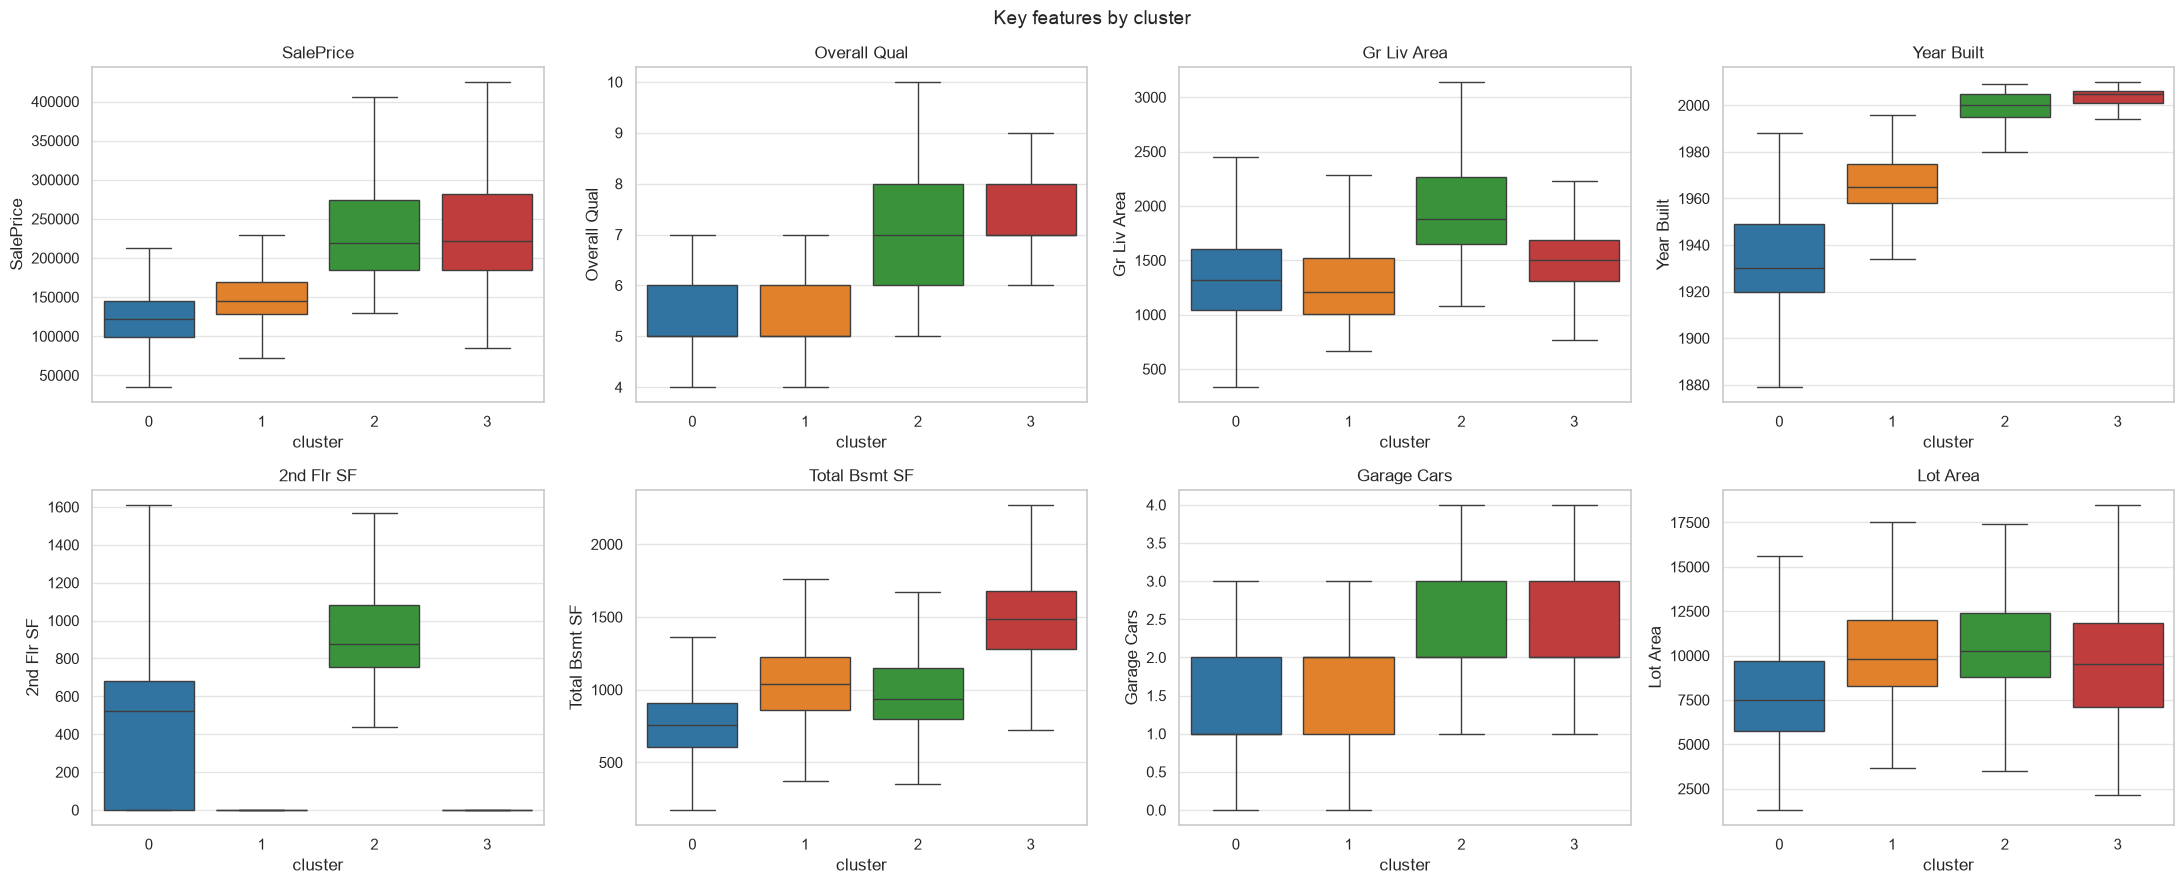

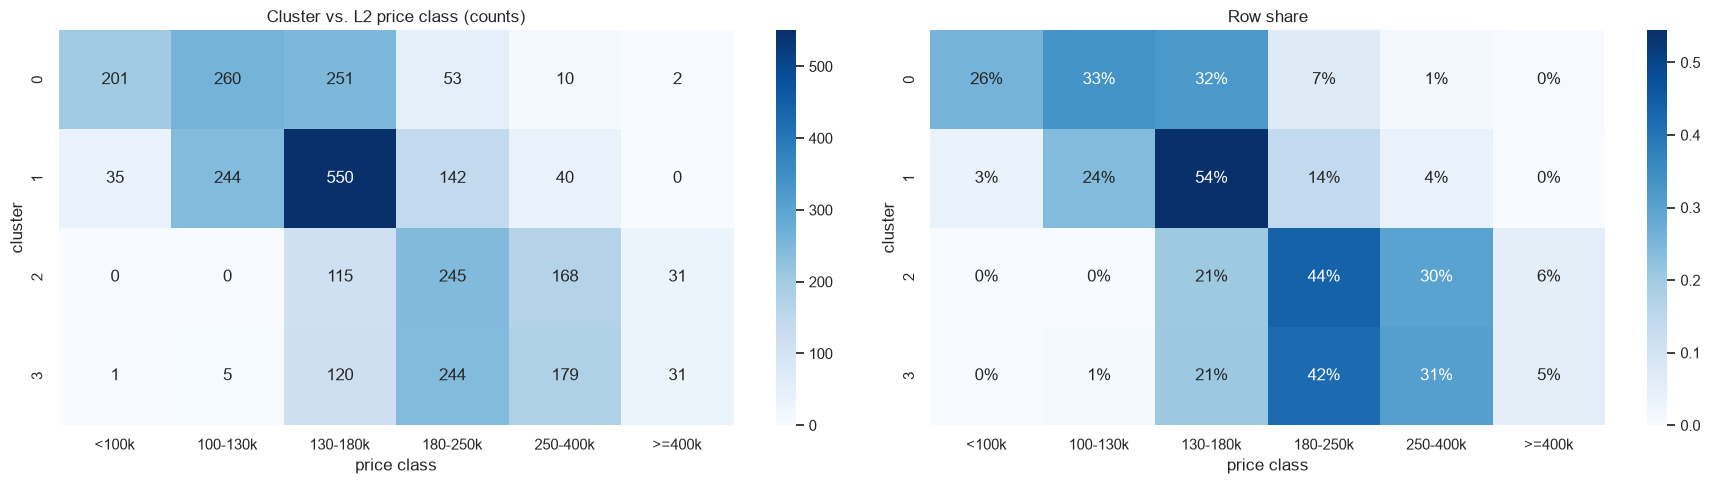

In [17]:
box_feats = ["SalePrice", "Overall Qual", "Gr Liv Area", "Year Built", "2nd Flr SF", "Total Bsmt SF", "Garage Cars", "Lot Area"]
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
palette = [cm.tab10(c) for c in range(K)]
for ax, f in zip(axes.ravel(), box_feats):
    sns.boxplot(data=prof, x="cluster", y=f, ax=ax, palette=palette, showfliers=False)
    ax.set_title(f)
plt.suptitle("Key features by cluster", fontsize=14); plt.tight_layout(); plt.show()

ct = pd.crosstab(pd.Series(cl, name="cluster"), pd.Series(np.array(CLASS_NAMES)[price_class], name="price class"))[CLASS_NAMES]
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=axes[0]); axes[0].set_title("Cluster vs. L2 price class (counts)")
sns.heatmap(ct.div(ct.sum(1), axis=0), annot=True, fmt=".0%", cmap="Blues", ax=axes[1]); axes[1].set_title("Row share")
plt.tight_layout(); plt.show()

### What characterises each cluster?

| Cluster | Houses | Typical house | Avg / median price |
|---|---|---|---|
| **0: old town houses** | 777 | Built around **1936**. 1.5- or 2-story, **small lots** (7,900 sq ft), in `OldTown`, `BrkSide`, `IDOTRR`. Brick or cinder-block foundation, **detached garage** (81 %), wood or metal siding. Average quality (5.2), weakest basements. | 126k / 122k |
| **1: post-war ranch houses** | 1,011 | Built around **1966**, 74 % **1-story**, almost no upper floor. Cinder-block foundation (91 %), attached garage. Mostly `NAmes`, `Sawyer`, `NWAmes`. **Largest lots** (11,600 sq ft). Average quality (5.5). | 154k / 145k |
| **2: modern 2-story family houses** | 559 | Built around **1998**, 95 % **2-story**. **Biggest living area** (1,975 sq ft), most bedrooms (3.3) and baths (2.9). Concrete foundation, vinyl siding, 2.3 garage spaces. `Gilbert`, `CollgCr`, `Somerst`. Good quality (7.1). | 241k / 219k |
| **3: modern 1-story houses and townhouses** | 580 | The **newest** (around **2002**), 96 % **1-story** but with a **big basement** (1,496 sq ft), so the total area is similar to cluster 2. 26 % townhouses. `CollgCr`, `NridgHt`, `Somerst`. Highest quality (7.3), best kitchens. | 243k / 221k |

**What we learn**
* The clusters mostly split houses by **age/construction era** (PC1) and **number of floors** (PC2/PC3), *not* directly by price.
* Price follows from the era: new houses are higher quality, so clusters 2 and 3 are expensive and 0 and 1 are cheaper. Clusters 2 and 3 have the same average price and differ only in style.
* The heatmap shows that each cluster still covers 4–5 of the 6 price classes. So the clusters are **not** price classes (ARI only 0.14).


## 7. New, invented houses

We invent a few houses and ask the model which cluster each one belongs to. For every column we don't specify, we use the most typical value (median for numbers, most frequent value for categories).

**Why must the new house go through PCA first?**
The k-means model lives in the *PCA space*: its cluster centres are points with 114 coordinates (the principal components), **not** points with 233 original columns. To compare a new house with those centres it must be converted into the same space, with exactly the same steps as the training data:
1. clean and one-hot encode it, with the **same columns** as before,
2. scale it with the **already fitted** min-max scaler (same min and max as the training data, never refit),
3. project it with the **already fitted** PCA.

If we refitted the scaler or PCA on the new house, the axes would mean something different, and the numbers could not be compared with the centres.

In [18]:
template = {}
for c in df_raw.columns:
    s = df_raw[c]
    template[c] = s.median() if pd.api.types.is_numeric_dtype(s) and c != "MS SubClass" else s.mode()[0]

def make_house(**kw):
    h = dict(template); h.update(kw)
    h.setdefault("Year Remod/Add", h["Year Built"])
    return h

new_houses = pd.DataFrame([
    make_house(Name="Old small cottage (OldTown, 1915)", Neighborhood="OldTown", **{
        "Year Built": 1915, "Year Remod/Add": 1960, "Overall Qual": 4, "Overall Cond": 5,
        "Gr Liv Area": 850, "1st Flr SF": 850, "2nd Flr SF": 0, "Total Bsmt SF": 600, "Bsmt Unf SF": 600,
        "BsmtFin SF 1": 0, "BsmtFin Type 1": "Unf", "Bsmt Qual": "Fa", "Full Bath": 1, "Half Bath": 0,
        "Bedroom AbvGr": 2, "TotRms AbvGrd": 5, "Garage Cars": 1, "Garage Area": 220, "Garage Type": "Detchd",
        "Garage Yr Blt": 1950, "Garage Finish": "Unf", "Kitchen Qual": "Fa", "Exter Qual": "TA",
        "Foundation": "BrkTil", "House Style": "1Story", "MS SubClass": 30, "MS Zoning": "RM",
        "Lot Area": 6000, "Lot Frontage": 50, "Fireplaces": 0, "Central Air": "N", "Heating QC": "Fa",
        "Exterior 1st": "Wd Sdng", "Exterior 2nd": "Wd Sdng"}),
    make_house(Name="1960s ranch (NAmes)", Neighborhood="NAmes", **{
        "Year Built": 1962, "Overall Qual": 5, "Overall Cond": 6, "Gr Liv Area": 1150, "1st Flr SF": 1150,
        "2nd Flr SF": 0, "Total Bsmt SF": 1100, "BsmtFin SF 1": 600, "Bsmt Unf SF": 500, "Full Bath": 1,
        "Half Bath": 1, "Bedroom AbvGr": 3, "TotRms AbvGrd": 6, "Garage Cars": 1, "Garage Area": 300,
        "Garage Type": "Attchd", "Garage Yr Blt": 1962, "Kitchen Qual": "TA", "Exter Qual": "TA",
        "Foundation": "CBlock", "House Style": "1Story", "MS SubClass": 20, "Lot Area": 9500,
        "Exterior 1st": "HdBoard", "Exterior 2nd": "HdBoard"}),
    make_house(Name="2000s family 2-story (CollgCr)", Neighborhood="CollgCr", **{
        "Year Built": 2003, "Overall Qual": 7, "Overall Cond": 5, "Gr Liv Area": 1850, "1st Flr SF": 950,
        "2nd Flr SF": 900, "Total Bsmt SF": 950, "BsmtFin SF 1": 700, "Bsmt Unf SF": 250, "BsmtFin Type 1": "GLQ",
        "Bsmt Qual": "Gd", "Full Bath": 2, "Half Bath": 1, "Bsmt Full Bath": 1, "Bedroom AbvGr": 3,
        "TotRms AbvGrd": 8, "Garage Cars": 2, "Garage Area": 520, "Garage Type": "Attchd", "Garage Yr Blt": 2003,
        "Garage Finish": "RFn", "Kitchen Qual": "Gd", "Exter Qual": "Gd", "Foundation": "PConc",
        "House Style": "2Story", "MS SubClass": 60, "Lot Area": 9000, "Fireplaces": 1, "Fireplace Qu": "Gd",
        "Exterior 1st": "VinylSd", "Exterior 2nd": "VinylSd"}),
    make_house(Name="New luxury house (NridgHt, 2008)", Neighborhood="NridgHt", **{
        "Year Built": 2008, "Overall Qual": 10, "Overall Cond": 5, "Gr Liv Area": 3000, "1st Flr SF": 2000,
        "2nd Flr SF": 1000, "Total Bsmt SF": 2000, "BsmtFin SF 1": 1500, "Bsmt Unf SF": 500, "BsmtFin Type 1": "GLQ",
        "Bsmt Qual": "Ex", "Bsmt Exposure": "Gd", "Full Bath": 3, "Half Bath": 1, "Bsmt Full Bath": 1,
        "Bedroom AbvGr": 4, "TotRms AbvGrd": 11, "Garage Cars": 3, "Garage Area": 850, "Garage Type": "BuiltIn",
        "Garage Yr Blt": 2008, "Garage Finish": "Fin", "Kitchen Qual": "Ex", "Exter Qual": "Ex", "Heating QC": "Ex",
        "Foundation": "PConc", "House Style": "2Story", "MS SubClass": 60, "Lot Area": 14000, "Lot Frontage": 100,
        "Fireplaces": 2, "Fireplace Qu": "Ex", "Mas Vnr Area": 400, "Mas Vnr Type": "Stone",
        "Exterior 1st": "CemntBd", "Exterior 2nd": "CmentBd", "Wood Deck SF": 250, "Open Porch SF": 120}),
    make_house(Name="Big but old & worn (Edwards, 1950)", Neighborhood="Edwards", **{
        "Year Built": 1950, "Overall Qual": 4, "Overall Cond": 3, "Gr Liv Area": 2100, "1st Flr SF": 1200,
        "2nd Flr SF": 900, "Total Bsmt SF": 1000, "Bsmt Unf SF": 1000, "BsmtFin SF 1": 0, "BsmtFin Type 1": "Unf",
        "Bsmt Qual": "TA", "Full Bath": 2, "Half Bath": 0, "Bedroom AbvGr": 4, "TotRms AbvGrd": 8,
        "Garage Cars": 1, "Garage Area": 280, "Garage Type": "Detchd", "Garage Yr Blt": 1950, "Garage Finish": "Unf",
        "Kitchen Qual": "TA", "Exter Qual": "TA", "Foundation": "CBlock", "House Style": "2Story", "MS SubClass": 50,
        "Lot Area": 11000, "Exterior 1st": "Wd Sdng", "Exterior 2nd": "Wd Sdng"}),
]).set_index("Name")

def predict_cluster(raw):
    Xn = encode(clean(raw.reset_index(drop=True)), columns=FEATURES)   # 1. same cleaning + same columns
    Zn = pca98.transform(scaler.transform(Xn))                          # 2. fitted scaler, 3. fitted PCA
    lab = models[0.98].predict(Zn)
    order = np.argsort(np.argsort(pd.Series(price).groupby(models[0.98].labels_).mean().to_numpy()))
    return order[lab], Zn

new_cl, Z_new = predict_cluster(new_houses)
dist = np.linalg.norm(Z_new[:, None, :] - centers[0.98][None, :, :], axis=2)
res = new_houses[["Neighborhood", "Year Built", "Overall Qual", "Gr Liv Area", "Total Bsmt SF", "Garage Cars", "House Style"]].copy()
res["cluster"] = new_cl
res["cluster mean price"] = [summary.loc["SalePrice", c] for c in new_cl]
for c in range(K): res[f"dist to C{c}"] = dist[:, c]
display(res.round(2))

,Neighborhood,Year Built,Overall Qual,Gr Liv Area,Total Bsmt SF,Garage Cars,House Style,cluster,cluster mean price,dist to C0,dist to C1,dist to C2,dist to C3
Name,,,,,,,,,,,,,
"Old small cottage (OldTown, 1915)",OldTown,1915,4,850,600,1,1Story,0,126112.74,3.50,4.22,4.92,4.74
1960s ranch (NAmes),NAmes,1962,5,1150,1100,1,1Story,1,153703.66,3.84,2.83,4.02,3.63
2000s family 2-story (CollgCr),CollgCr,2003,7,1850,950,2,2Story,2,241486.63,4.02,3.81,2.60,3.26
"New luxury house (NridgHt, 2008)",NridgHt,2008,10,3000,2000,3,2Story,2,241486.63,4.55,4.48,3.60,4.12
"Big but old & worn (Edwards, 1950)",Edwards,1950,4,2100,1000,1,2Story,0,126112.74,3.37,3.62,4.01,4.35


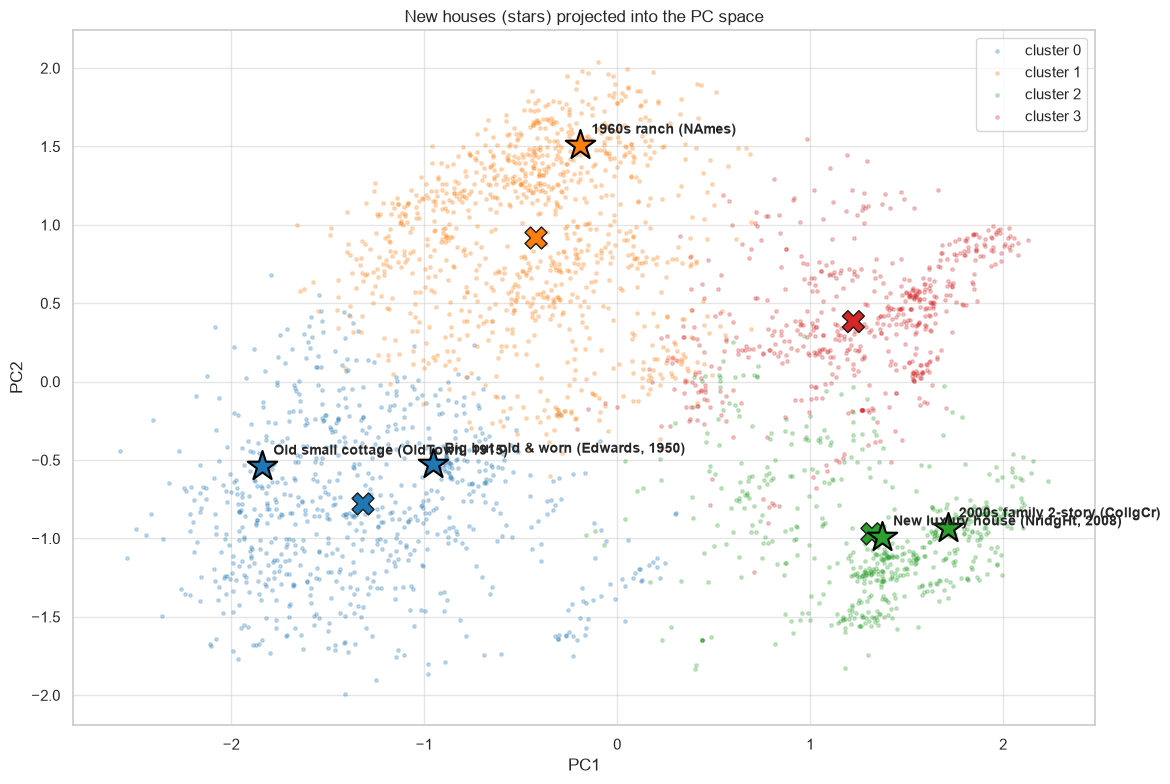

In [19]:
fig, ax = plt.subplots(figsize=(12, 8))
for c in range(K):
    m = cl == c
    ax.scatter(Z98[m, 0], Z98[m, 1], s=6, alpha=0.25, color=cm.tab10(c), label=f"cluster {c}")
ax.scatter(centers[0.98][:, 0], centers[0.98][:, 1], marker="X", s=250, c=[cm.tab10(c) for c in range(K)], edgecolor="k")
for (name, z), c in zip(zip(new_houses.index, Z_new), new_cl):
    ax.scatter(z[0], z[1], marker="*", s=500, color=cm.tab10(c), edgecolor="black", linewidth=1.5)
    ax.annotate(name, (z[0], z[1]), xytext=(8, 8), textcoords="offset points", fontsize=10, weight="bold")
ax.set(xlabel="PC1", ylabel="PC2", title="New houses (stars) projected into the PC space")
ax.legend(); plt.tight_layout(); plt.show()

### Are the assignments plausible?

| Invented house | Cluster | Does it make sense? |
|---|---|---|
| Small cottage, 1915, OldTown, brick foundation, detached garage | **0** (old town) | **Yes.** Era, location, foundation and garage all match cluster 0. |
| 1960s ranch, NAmes, 1-story, cinder-block foundation | **1** (post-war ranch) | **Yes.** It is the typical cluster-1 house (distance to its centre only 2.83). |
| 2003 family 2-story, CollgCr, vinyl siding | **2** (modern 2-story) | **Yes.** Closest of all to its centre (2.60). |
| 2008 luxury house, NridgHt, quality 10, 3000 sq ft | **2** (modern 2-story) | **Right style, but too coarse.** It is a modern 2-story house, so cluster 2 is correct. But it is far from every centre (3.60): no cluster represents "luxury", so a 600k house and a 200k house of the same style and era land in the same cluster. |
| Big but worn 1950 house, Edwards, 2-story, quality 4 | **0** (old town) | **Plausible.** Old, detached garage, unfinished basement, wood siding. It lies between clusters 0 and 1 (distances 3.37 vs. 3.62). Size alone does not make it modern. |

**Why transform with PCA first?** The cluster centres only exist in the PCA space (114 coordinates). A new house with 233 raw columns cannot be compared with them. We therefore must apply the **same** encoder, the **same already-fitted** scaler and the **same already-fitted** PCA. If we refit them on the new house, the axes change meaning (and the number of columns would not even match).

**Main lesson:** the model groups houses by era and style. It works well for "typical" houses, but it cannot recognise a *luxury* house as special.


## 8. Bonus: interactive 3D plots

For each of the four clusterings we plot the first three principal components in 3D (you can rotate and zoom):
* **left (a):** coloured by k-means cluster; the diamonds are the centroids
* **right (b):** coloured by the six price classes from L2 (blue = most expensive, then green, gold, orange, red, purple = cheapest)

Hover over a point to see its price and key facts.

In [20]:
CLUSTER_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f"]
PRICE_COLORS = {5: "#1f4fd8", 4: "#2ca02c", 3: "#e6b800", 2: "#ff7f0e", 1: "#d62728", 0: "#7b2cbf"}
hover = [f"${p:,.0f} | Qual {q} | {a} sqft | built {y} | {n}" for p, q, a, y, n in
         zip(price, df["Overall Qual"], df["Gr Liv Area"], df["Year Built"], df["Neighborhood"])]

def plot3d(t):
    Zt, lab, cen = Z[t][:, :3].round(3), labels[t], centers[t][:, :3].round(3)
    fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]],
                        subplot_titles=(f"(a) k-means clusters (k={K})", "(b) L2 price classes"), horizontal_spacing=0.02)
    for c in range(K):
        m = lab == c
        fig.add_trace(go.Scatter3d(x=Zt[m, 0], y=Zt[m, 1], z=Zt[m, 2], mode="markers", name=f"cluster {c}",
                                   marker=dict(size=2.5, color=CLUSTER_COLORS[c], opacity=0.6),
                                   text=np.array(hover)[m], hoverinfo="text", legendgroup="cl"), 1, 1)
    fig.add_trace(go.Scatter3d(x=cen[:, 0], y=cen[:, 1], z=cen[:, 2], mode="markers", name="centroids",
                               marker=dict(size=9, symbol="diamond", color=CLUSTER_COLORS[:K], line=dict(color="black", width=3))), 1, 1)
    for k in range(5, -1, -1):
        m = price_class == k
        fig.add_trace(go.Scatter3d(x=Zt[m, 0], y=Zt[m, 1], z=Zt[m, 2], mode="markers", name=CLASS_NAMES[k],
                                   marker=dict(size=2.5, color=PRICE_COLORS[k], opacity=0.6),
                                   text=np.array(hover)[m], hoverinfo="text", legendgroup="pc"), 1, 2)
    fig.add_trace(go.Scatter3d(x=cen[:, 0], y=cen[:, 1], z=cen[:, 2], mode="markers", name="centroids ",
                               marker=dict(size=9, symbol="diamond", color="black")), 1, 2)
    axes = dict(xaxis_title="PC1", yaxis_title="PC2", zaxis_title="PC3")
    fig.update_layout(height=650, width=1300, title=f"{int(t*100)} % variance ({N_PC[t]} PCs) — first 3 PCs",
                      scene=axes, scene2=axes, legend=dict(itemsizing="constant"), margin=dict(l=0, r=0, t=60, b=0))
    fig.show()

for t in THRESHOLDS:
    plot3d(t)

### Is k-means a good choice? Comparison with other methods

k-means works best when clusters are round blobs of similar size. We compare it (same data, same number of clusters) with a **Gaussian mixture** (allows oval-shaped clusters) and **Ward hierarchical clustering** (builds clusters by merging the closest ones step by step). We also check how well each method matches the price classes.

In [21]:
Zc = Z[0.98]
alts = {
    "k-means": labels[0.98],
    "Gaussian mixture (diag)": GaussianMixture(K, covariance_type="diag", random_state=SEED, n_init=3).fit(Zc).predict(Zc),
    "Agglomerative (Ward)": AgglomerativeClustering(K, linkage="ward").fit_predict(Zc),
}
rows = [{"method": n, "silhouette": silhouette_score(Zc, l), "ARI vs k-means": adjusted_rand_score(labels[0.98], l),
         "ARI vs price class": adjusted_rand_score(price_class, l),
         "cluster sizes": sorted(np.bincount(l).tolist(), reverse=True)} for n, l in alts.items()]
display(pd.DataFrame(rows).round(3))

# How well do PC1..PC3 alone separate price? (Spearman correlation of each PC with SalePrice)
from scipy.stats import spearmanr
display(pd.DataFrame({f"PC{i+1}": [spearmanr(Zc[:, i], price)[0]] for i in range(5)}, index=["Spearman ρ with SalePrice"]).round(3))

,method,silhouette,ARI vs k-means,ARI vs price class,cluster sizes
0,k-means,0.096,1.000,0.143,"[1011, 777, 580, 559]"
1,Gaussian mixture (diag),-0.028,0.089,0.039,"[1210, 885, 668, 164]"
2,Agglomerative (Ward),0.067,0.595,0.105,"[1219, 684, 668, 356]"


,PC1,PC2,PC3,PC4,PC5
Spearman ρ with SalePrice,0.799,-0.006,-0.113,-0.02,-0.196


### Bonus interpretation

**(a) What do the 3D plots show?**
* The modern houses on the right form **two arms** (2-story and 1-story). They are already visible in the 2D plot, and PC3 pulls them further apart. This is the structure behind the elbow at k = 4: with k = 3 both arms are merged.
* The arms are **long and curved**, not round blobs. Inside the arms there are small bands, probably single neighbourhoods or developments built by the same builder with identical materials. The old houses on the left form a **loose cloud** without a clear shape.
* The clusters **touch each other**, with no empty gap between them. A few houses (townhouses, duplexes) lie alone at the edges.
* All four thresholds look the same, since the first 3 PCs are identical in all of them.

**Is k-means a good fit? Only partly.**
* k-means assumes **round, similar-sized blobs**. It cuts the space into straight-edged regions. Curved arms and a continuum without gaps break this assumption, which is why the silhouette stays near 0.1.
* In 114 dimensions, all distances become similar (the *curse of dimensionality*), which hurts every distance-based method.
* **Alternatives:** *Ward hierarchical clustering* gives similar groups (ARI 0.60 compared with k-means). A *Gaussian mixture* did not help here (silhouette below 0), because it needs many parameters in 114 dimensions and our columns are mostly 0/1. *DBSCAN/HDBSCAN* could follow the curved arms and mark odd houses as noise, but it needs fewer dimensions (say 10–20 PCs) and careful tuning. For data with many categories, *k-prototypes* is designed for mixed numeric and categorical columns.
* **Verdict:** k-means gives a **useful and easy-to-explain** grouping (era × style), but it is a sensible cut through a continuum, not a natural split into separate groups.

**(b) Clusters vs. the six price classes**
* The price classes form a **colour gradient along PC1**: cheap (purple/red) on the left, expensive (green/blue) at the far end of the two modern arms. PC1 correlates 0.80 with price, while PC2 and PC3 hardly correlate with it (0.00 and −0.11).
* But k-means clusters are separated by **PC2/PC3** (1-story vs. 2-story) as much as by PC1. The most expensive houses (≥400k) are **not a cluster of their own**; they sit at the outer ends of clusters 2 and 3. This is why the agreement is low (**ARI = 0.14**).
* **Why? Feature importance.** In L2, the price model relied mostly on `Overall Qual`, `Gr Liv Area`/`Total SF`, quality × area and neighbourhood. In our PCA those features get small loadings, because PCA is dominated by dummies (materials, foundation, garage type, house style). **PCA looks for variance, not for what predicts price.** The big components describe *how* a house was built, not *what it is worth*. Size, the second most important price driver, is spread over many small components.
* **Takeaway:** unsupervised clustering finds structure, but not necessarily the structure we care about. To separate price classes we need supervised learning (as in L2).


## Conclusions

**In plain words**

1. **PCA works, but only moderately.** 233 features → 114 / 82 / 59 / 35 components for 98 / 95 / 90 / 80 % of the variance. The reduction is limited because most columns are independent 0/1 dummies.
2. **k = 4 clusters.** The elbow method says 4; the silhouette slightly prefers 3. All silhouettes are low (≈ 0.1): houses form a smooth continuum, not separate groups. The number of kept components (80–98 %) hardly changes the clusters (ARI ≥ 0.97), so 80 % is enough.
3. **Scaling matters more than the number of components.** Min-max is stable and easy to interpret. Z-score gives too much weight to rare categories. L2 normalisation of raw data is dominated by `Lot Area` and years. A log transform barely changes min-max, but changes the other two a lot.
4. **What the components mean.** PC1 = how new the house is (ρ = 0.80 with price). PC2/PC3 = 1-story vs. 2-story. PC4 = single-family house vs. townhouse.
5. **What the clusters mean.** (0) old town houses, (1) post-war ranch houses, (2) modern 2-story houses, (3) modern 1-story houses and townhouses. Price follows from the era, but the clusters are **not** the price classes (ARI 0.14), because PCA captures *how houses are built*, not *what they cost*.
6. **New houses** are assigned sensibly, as long as they go through the same encoder, scaler and PCA as the training data. A luxury house gets no cluster of its own.
